# 02 — Data preparation: Census-tract master table

This notebook builds the **Census-tract-level master table** for the Atlanta energy and urban-morphology
study. It is notebook 01 with the study unit changed from ZIP to tract: the same sources, the same
aggregation code, and the same column groups in the same order. It starts from the 2010 Census tract
polygons of the energy-study tracts, then joins one data source per section:

- distance to the CBD
- MARTA rail access
- walkability
- Microsoft building footprints
- 2011 ACS/Census socioeconomic variables
- ARC LandPro 2012 land use
- EPA EQUATES CMAQ air quality (July 2010)
- remote-sensing rasters: NDVI, impervious surface, land surface temperature, leaf area index
- NLCD 2011 land cover (complete for every tract, unlike LandPro)

Every step, check and figure is in this notebook. Nothing runs in hidden scripts.

**Study unit.** 2010 Census tracts (TIGER/Line 2010). The **study tracts** are the 174 tracts for which
the prior energy model (Random Forest and MATLAB regression) produced tract-level estimates: 50 in the
HIGH-cluster workbook and 124 in the LOW-cluster workbook (Section 3a). The three predictions are RF train,
RF cross-validated and MATLAB.

**What differs from the ZIP table (notebook 01).**
- **Keys and names.** `ZIP5` becomes `TractGeoID` (the 11-character 2010 tract GEOID), and every
  `*_zip` column becomes `*_tract`. The TIGER ZCTA base fields are replaced by the TIGER tract fields.
  The ZIP-only raw fields (`energy_kwh`, `zipcode`, `OBJECTID_1`, `OBJECTID_2`, `ZCTA`, `Shape_Leng`,
  `Shape_Area`) have no tract source and are omitted.
- **No observed energy.** Observed residential energy is available only at ZIP level; the source tract
  values are 0 placeholders. `energy_actual_kwh` is therefore NaN for every tract.
- **No prediction filter.** The ZIP table keeps only ZIPs whose three predictions are all positive. Here every
  study tract is kept, and the new boolean `matlab_negative` flags the tracts whose MATLAB prediction is
  negative.
- **Socioeconomic variables** are joined from the tract table that notebook 01 saved
  (`data/interim/socioeconomic_tract.csv`), not re-parsed from the Excel workbook.
- **Counts** that notebook 01 states as fixed ZIP numbers (190, 142, 48, ...) are computed from the tract data.

**Coordinate reference system.** All geometry work is done in **EPSG:2240**, NAD83 / Georgia West
(US survey feet). This is the projection used throughout the ArcGIS methodology.

**Units.**
- Areas are in **square feet** (`_sqft`), and ratios are per square foot.
- Distances are computed in feet and reported in **miles** (`_mi`, 1 mi = 5,280 ft).

**Pipeline.**
1. `data/raw`: inputs, never modified.
2. `data/interim`: the base and joined tract layers (the socioeconomic codebook and tract table come
   from notebook 01).
3. `data/processed`: the data dictionary and the master table as CSV and Excel.

### Data sources

| Dataset | Source | Vintage | Native CRS | Variables produced |
|---|---|---|---|---|
| Tract polygons | TIGER/Line 2010 Census tracts for Georgia, exported from ArcGIS Pro | 2010 | EPSG:2240 | TIGER tract fields, `TractGeoID`, `tract_area_sqft` |
| Tract energy estimates | The prior energy model (RF and MATLAB), HIGH and LOW cluster workbooks | as the ZIP model, c. 2011 | tables | `pred_*_kwh`, `cluster`, `lat`, `lon`, `matlab_negative` |
| Atlanta CBD boundary | Provided with the study data | to be confirmed | EPSG:4269 | `Dist_CBD_mi` |
| MARTA rail stations | MARTA / Atlanta open data | 2025 | EPSG:3857 | `MARTA_stations_in_tract`, `has_MARTA_station`, `Dist_MARTA_Rail_mi`, `Nearest_MARTA_Station` |
| EPA National Walkability Index v3.0 | US EPA | v3.0 | EPSG:2240 | `NatWalkInd_tract`, `D3B_tract` |
| Microsoft US Building Footprints | Microsoft | imagery 2018–2020 | EPSG:4326 | `ms_*` |
| Tract socioeconomic table | Compilation of 2011 ACS/Census variables, provided with the study data; cleaned in notebook 01 | 2011 | tables | `pop`, `se_v001` … `se_v356` |
| ARC LandPro 2012 | Atlanta Regional Commission (public open data) | 2012 | EPSG:2240 | `landpro_coverage_frac`, `lu_pct_*` |
| EPA EQUATES CMAQ v5.3.2, 12US1 grid | US EPA (public) | July 2010 (daily) | 12 km Lambert Conformal Conic grid (CSV) | `aq_*_jul2010` |
| Remote-sensing rasters | Landsat 4-5 TM (NDVI, LST); MRLC Annual NLCD (impervious); a 500 m LAI product | 2011–2012 (impervious 2011) | EPSG:4326 | `rs_*` |
| NLCD 2011 Land Cover, CONUS (2011 edition, released 2014) | USGS / MRLC (public) | 2011 | 30 m Albers Conical Equal Area (CONUS) | `nlcd11_*` |

### Conventions
- **Join keys are text.** `TractGeoID` is a zero-padded 11-character string (state + county + tract).
  Numeric keys lost leading zeros and broke joins in the ArcGIS workflow (methodology §9).
- **Distances are Euclidean**, measured from each tract's representative point. This is a deliberate
  choice (methodology §3), documented as a limitation.
- **MATLAB predictions are unreliable** (many tract estimates are negative). The column is kept and the
  negatives are flagged in `matlab_negative`, but it should not be used for cross-scale comparisons
  without a caveat.
- **The HIGH/LOW cluster labels** are analyst judgment calls, not an established standard.

Background:
- [`docs/atlanta_methodology_arcgis.md`](../docs/atlanta_methodology_arcgis.md): the ArcGIS workflow
  this notebook reproduces.
- [`01_data_preparation.ipynb`](01_data_preparation.ipynb): the ZIP-level notebook this one mirrors.

## Reproducing this notebook

**Environment.** Python 3.13. From the repository root:

```bash
python -m venv .venv
.venv/Scripts/python -m pip install -r requirements.txt   # macOS/Linux: .venv/bin/python
.venv/Scripts/python -m ipykernel install --user --name atlanta-energy-morphology
```

`requirements.txt` pins the exact versions used for the committed run. Select the
`atlanta-energy-morphology` kernel.

**Run notebook 01 first.** This notebook reads `data/interim/socioeconomic_tract.csv` and
`data/interim/socioeconomic_codebook.csv`, which notebook 01 (Section 8) writes.

**Raw inputs.** `data/` is gitignored, so place these files under `data/raw/` first. All paths in the
notebook are relative to `notebooks/`.

| Path under `data/raw/` | Content | Source |
|---|---|---|
| `vectors/tiger_tracts_2010_georgia.gpkg` | Georgia 2010 Census tract polygons (1,969 tracts, EPSG:2240) with the TIGER fields only: `STATEFP10`, `COUNTYFP10`, `TRACTCE10`, `GEOID10`, `NAME10`, `NAMELSAD10`, `MTFCC10`, `FUNCSTAT10`, `ALAND10`, `AWATER10`, `INTPTLAT10`, `INTPTLON10` | TIGER/Line 2010 tracts ([Census Bureau](https://www.census.gov/geographies/mapping-files/time-series/geo/tiger-line-file.html)), exported from ArcGIS Pro to GeoPackage. The ArcGIS layer's own energy fields were dropped, and so was one empty row (no GEOID, no geometry). |
| `vectors/cbd_atlanta.gpkg` | Atlanta CBD boundary polygon | Provided with the study data, not redistributed |
| `vectors/MARTA_railstations_2025_georgia_zipcode.gpkg` (layer `marta_rail_stations`) | 38 MARTA rail stations | MARTA / Atlanta open data (public) |
| `vectors/EPA_walkabilityindex_2025_georgia_blockgroup.gpkg` | Georgia block groups with the National Walkability Index | [EPA National Walkability Index v3.0](https://www.epa.gov/smartgrowth/smart-location-mapping) (public) |
| `vectors/georgia_building_length_microsoft.gpkg` | Georgia building footprints, converted from GeoJSON with `ogr2ogr -f GPKG` | [Microsoft US Building Footprints](https://github.com/microsoft/USBuildingFootprints) (public) |
| `tables/highEE_FullData.xlsx`, `tables/lowEE_FullData.xlsx` | The model workbooks for the HIGH and LOW clusters: tract IDs and coordinates (sheets `Census Coordinates` and `testCoordinates`) and tract estimates (sheet `censusEstimates`) | Provided with the study data, not redistributed |
| `vectors/LandPro_2012.shp` (with `.shx`, `.dbf`, `.prj`, `.cpg`, `.shp.xml`) | ARC LandPro 2012 land-use polygons for the Atlanta Regional Commission region | Atlanta Regional Commission open data (public); committed to the repository |
| `tables/Daily_EQUATES_CMAQv532_cb6r3_ae7_aq_STAGE_12US1_201007.csv` | Daily CMAQ air-quality output for the continental US 12 km grid, July 2010 | [EPA EQUATES](https://www.epa.gov/cmaq/equates) (public). The file is large (816 MB) and is **not committed**; download it separately. |
| `rasters/ga_ndvi_2011_2012-002.tif`, `rasters/ga_impervious_2011.tif`, `rasters/ga_lst_2011_2012-001.tif`, `rasters/ga_lai_2011_2012.tif` | Georgia-wide single-band GeoTIFFs (EPSG:4326): NDVI, fractional impervious surface, land surface temperature, leaf area index | NDVI and LST: Landsat 4-5 TM via [USGS EarthExplorer](https://earthexplorer.usgs.gov/); impervious: [MRLC Annual NLCD](https://www.mrlc.gov/); LAI: a 500 m LAI product (all public). NDVI and LST are large (2.2 and 2.7 GB) and are **not committed**. |
| `rasters/nlcd_2011_land_cover/` (the unzipped `nlcd_2011_landcover_2011_edition_2014_10_10.zip`: `.img` header with its `.ige` data and `.rrd` overviews, 18 GB) | NLCD 2011 Land Cover, conterminous US, 30 m, 16 classes | [USGS ScienceBase, doi:10.5066/P97S2IID](https://www.sciencebase.gov/catalog/item/5dfc2280e4b0b207a9fe8235) (public; mirror at [MRLC](https://www.mrlc.gov/data)). CONUS-wide and large; **not committed**. |

**Run.** From `notebooks/`:

```bash
../.venv/Scripts/python -m jupyter nbconvert --to notebook --execute --inplace --ExecutePreprocessor.timeout=-1 02_tract_preparation.ipynb
```

A full run takes tens of minutes, mostly spent loading and reprojecting the ~4 million Microsoft
footprints, overlaying the LandPro polygons, scanning the air-quality CSV and reading the rasters
(including the CONUS NLCD window).

## 1. Setup

Imports, paths and the shared helpers:

- **`plot_choropleth` / `plot_choropleths`**: static geopandas/matplotlib maps, which render on GitHub
  and in PDF exports. Tracts with no value are drawn in hatched grey. `plot_choropleths` can also save its
  figure to a PNG.
- **`sanity_report`**: a summary table (n, nulls, quartiles, zeros, negatives) plus histograms.
- **`join_tract`**: a one-to-one left join on `TractGeoID`. It prints how many tracts received each new column.

In [1]:
import math
import re
from pathlib import Path

import geopandas as gpd
import matplotlib.pyplot as plt
from matplotlib.patches import Patch
import numpy as np
import pandas as pd
import rasterio
from rasterio.enums import Resampling
from rasterio.features import rasterize
from rasterio.windows import from_bounds
from IPython.display import display
from shapely.geometry import box

RAW_VECTORS = Path("../data/raw/vectors")
RAW_TABLES = Path("../data/raw/tables")
RAW_RASTERS = Path("../data/raw/rasters")
INTERIM = Path("../data/interim")
PROCESSED = Path("../data/processed")
FIGURES = Path("../figures")
INTERIM.mkdir(parents=True, exist_ok=True)
PROCESSED.mkdir(parents=True, exist_ok=True)

TARGET_CRS = "EPSG:2240"  # NAD83 / Georgia West (US survey feet), as in the ArcGIS methodology
FT_PER_MI = 5280

plt.rcParams.update({"figure.dpi": 80, "axes.titlesize": 10, "axes.labelsize": 9})
pd.set_option("display.max_columns", 50)
pd.set_option("display.width", 200)


def plot_choropleth(gdf, col, title, ax=None, cmap="viridis", overlay=None, legend_label=None):
    """Static choropleth of one column; missing values hatched grey; `overlay` drawn on top in red."""
    ax = ax or plt.subplots(figsize=(6, 5.5))[1]
    data = gdf[[col, "geometry"]].copy()
    kwargs = dict(column=col, ax=ax, cmap=cmap, legend=True, edgecolor="white", linewidth=0.2,
                  missing_kwds={"color": "lightgrey", "hatch": "///", "label": "No data"})
    if pd.api.types.is_bool_dtype(data[col]) or not pd.api.types.is_numeric_dtype(data[col]):
        data[col] = data[col].astype(str)
        kwargs.update(categorical=True, legend_kwds={"title": legend_label, "loc": "lower left", "fontsize": 8})
    else:
        kwargs["legend_kwds"] = {"label": legend_label or col, "shrink": 0.7}
    data.plot(**kwargs)
    if overlay is not None:
        overlay.plot(ax=ax, color="red", markersize=14, edgecolor="black", linewidth=0.4, zorder=3)
    ax.set_title(title)
    ax.set_axis_off()
    return ax


def plot_choropleths(gdf, cols, titles, ncols=2, legend_labels=None, savepath=None, **kwargs):
    """Grid of choropleths, one panel per column; saved to `savepath` (PNG) if given."""
    nrows = math.ceil(len(cols) / ncols)
    fig, axes = plt.subplots(nrows, ncols, figsize=(6 * ncols, 5 * nrows), squeeze=False)
    for ax, col, title, lab in zip(axes.flat, cols, titles, legend_labels or cols):
        plot_choropleth(gdf, col, title, ax=ax, legend_label=lab, **kwargs)
    fig.tight_layout()
    if savepath:
        fig.savefig(savepath, bbox_inches="tight")
    plt.show()


def sanity_report(df, cols, hist=True):
    """Summary table (n, nulls, quartiles, zeros, negatives) and histograms."""
    x = df[cols].astype("float64")
    report = pd.DataFrame({
        "n": x.count(), "n_null": x.isna().sum(), "pct_null": (x.isna().mean() * 100).round(1),
        "min": x.min(), "p25": x.quantile(0.25), "median": x.median(), "p75": x.quantile(0.75), "max": x.max(),
        "n_zero": (x == 0).sum(), "n_negative": (x < 0).sum(),
    })
    display(report)
    if hist:
        ncols = min(4, len(cols))
        axes = x.hist(bins=30, color="steelblue", grid=False, layout=(math.ceil(len(cols) / ncols), ncols),
                      figsize=(3.6 * ncols, 2.8 * math.ceil(len(cols) / ncols)))
        plt.tight_layout()
        plt.show()


def join_tract(gdf, new):
    """One-to-one left join of `new` (indexed by TractGeoID) onto `gdf`; prints the match count per column."""
    out = gdf.join(new, on="TractGeoID", validate="one_to_one")
    assert len(out) == len(gdf)
    print(out[new.columns].notna().sum().rename(f"tracts matched (of {len(out)})").to_string())
    return out

## 2. Vector inventory and CRS

**Data.** Every layer of every GeoPackage in `data/raw/vectors`.

**Method.** Only the CRS of each layer is read here. Layers not already in EPSG:2240 are reprojected on
load with `.to_crs(TARGET_CRS)`, which leaves layers already in EPSG:2240 unchanged.

**Why EPSG:2240.**
- It is the projection of the ArcGIS workflow being reproduced, so areas and distances are directly
  comparable with it.
- It is a conformal projection designed for this part of Georgia, so planar distances and areas are
  accurate to well under 0.1% across the study area.

**Caveats.**
- The MARTA GeoPackage has two layers, so the station layer is always loaded by name.
- "ft" means US survey feet. The 2 ppm difference from international feet is negligible.
- LandPro (Section 9) is a shapefile, not a GeoPackage, and is already in EPSG:2240.
- The rasters (Section 11) stay on their native EPSG:4326 grid; the tracts are reprojected to them instead.

In [2]:
pd.DataFrame(
    [{"file": f.name, "layer": layer, "crs": gpd.read_file(f, layer=layer, rows=1).crs.to_string()}
     for f in sorted(RAW_VECTORS.glob("*.gpkg")) for layer in gpd.list_layers(f)["name"]]
).assign(matches_target=lambda d: d["crs"] == TARGET_CRS)

,file,layer,crs,matches_target
0,cbd_atlanta.gpkg,atlanta_cbd,EPSG:4269,False
1,EPA_walkabilityindex_2025_georgia_blockgroup.gpkg,walkability_index,EPSG:2240,True
2,georgia_building_length_microsoft.gpkg,georgia_building_length_microsoft,EPSG:4326,False
3,MARTA_railstations_2025_georgia_zipcode.gpkg,marta_rail_stations,EPSG:3857,False
4,MARTA_railstations_2025_georgia_zipcode.gpkg,walkability_index,EPSG:2240,True
5,tiger_energyclusters_2010_georgia_zipcode.gpkg,tiger_energyclusters_2010_georgia_zipcode,EPSG:2240,True
6,tiger_tracts_2010_georgia.gpkg,tiger_tracts_2010_georgia,EPSG:2240,True


## 3. Base layer: study tracts

**Data.** `tiger_tracts_2010_georgia.gpkg` holds the 1,969 Georgia 2010 Census tracts (TIGER/Line 2010
attributes only) in EPSG:2240. The energy estimates come from the two model workbooks, not from this layer.
The table below documents every column.

**Method.**
- **3a** builds the study frame from the model workbooks (tract ID, cluster, coordinates and the three
  estimates) and keeps only those tracts from the layer.
- **3b** renames the estimates, flags negative MATLAB estimates, sets the observed energy to NaN, and takes
  the population from the socioeconomic table.
- **3c** builds a text join key and the tract area.

The base layer is saved **before** any join.

**Caveats.**
- The layer has one row per tract. The ArcGIS export it was made from held one extra row with no GEOID and
  no geometry, which was removed when the layer was written. The code asserts that `GEOID10` is unique.
- `INTPTLAT10` and `INTPTLON10` are text in the TIGER source (for example `+33.5194018`) and are kept as
  delivered. The numeric coordinates used by the model are `lat` and `lon` (Section 3a).

In [3]:
tract_gdf = gpd.read_file(RAW_VECTORS / "tiger_tracts_2010_georgia.gpkg").to_crs(TARGET_CRS)

BASE_COLUMN_DOCS = pd.DataFrame(
    [
        ("STATEFP10", "State FIPS code (13 = Georgia)", "code", "TIGER/Line 2010 census tract"),
        ("COUNTYFP10", "County FIPS code", "code", "TIGER/Line 2010 census tract"),
        ("TRACTCE10", "6-digit census tract code", "code", "TIGER/Line 2010 census tract"),
        ("GEOID10", "State + county + tract FIPS; source of the TractGeoID key", "code", "TIGER/Line 2010 census tract"),
        ("NAME10", "Census tract number", "text", "TIGER/Line 2010 census tract"),
        ("NAMELSAD10", "Census tract name with its legal/statistical area description", "text", "TIGER/Line 2010 census tract"),
        ("MTFCC10", "MAF/TIGER feature class code", "code", "TIGER/Line 2010 census tract"),
        ("FUNCSTAT10", "Functional status", "code", "TIGER/Line 2010 census tract"),
        ("ALAND10", "Land area (not used; see tract_area_sqft)", "sq m", "TIGER/Line 2010 census tract"),
        ("AWATER10", "Water area", "sq m", "TIGER/Line 2010 census tract"),
        ("INTPTLAT10", "Latitude of the Census internal point (text)", "degrees", "TIGER/Line 2010 census tract"),
        ("INTPTLON10", "Longitude of the Census internal point (text)", "degrees", "TIGER/Line 2010 census tract"),
    ],
    columns=["column", "description", "unit", "source"],
)
assert set(BASE_COLUMN_DOCS["column"]) == set(tract_gdf.columns.drop("geometry"))
display(BASE_COLUMN_DOCS.assign(dtype=BASE_COLUMN_DOCS["column"].map(tract_gdf.dtypes.astype(str)),
                                n_null=BASE_COLUMN_DOCS["column"].map(tract_gdf.isna().sum())))

print(f"tracts: {len(tract_gdf)}, unique GEOID10: {tract_gdf['GEOID10'].nunique()}")
assert tract_gdf["GEOID10"].is_unique and (tract_gdf["GEOID10"].str.len() == 11).all() and (tract_gdf["STATEFP10"] == "13").all()
assert (tract_gdf["GEOID10"] == tract_gdf["STATEFP10"] + tract_gdf["COUNTYFP10"] + tract_gdf["TRACTCE10"]).all()

,column,description,unit,source,dtype,n_null
0,STATEFP10,State FIPS code (13 = Georgia),code,TIGER/Line 2010 census tract,str,0
1,COUNTYFP10,County FIPS code,code,TIGER/Line 2010 census tract,str,0
2,TRACTCE10,6-digit census tract code,code,TIGER/Line 2010 census tract,str,0
3,GEOID10,State + county + tract FIPS; source of the Tra...,code,TIGER/Line 2010 census tract,str,0
4,NAME10,Census tract number,text,TIGER/Line 2010 census tract,str,0
5,NAMELSAD10,Census tract name with its legal/statistical a...,text,TIGER/Line 2010 census tract,str,0
6,MTFCC10,MAF/TIGER feature class code,code,TIGER/Line 2010 census tract,str,0
7,FUNCSTAT10,Functional status,code,TIGER/Line 2010 census tract,str,0
8,ALAND10,Land area (not used; see tract_area_sqft),sq m,TIGER/Line 2010 census tract,float64,0
9,AWATER10,Water area,sq m,TIGER/Line 2010 census tract,float64,0


tracts: 1969, unique GEOID10: 1969


### 3a. Study frame

The study tracts are those listed in the two model workbooks:

| Workbook | Tract IDs | Estimates | Cluster |
|---|---|---|---|
| `highEE_FullData.xlsx` | sheet `Census Coordinates`, column `Census` | sheet `censusEstimates` | `HIGH` |
| `lowEE_FullData.xlsx` | sheet `testCoordinates`, column `Census` | sheet `censusEstimates` | `LOW` |

The `censusEstimates` sheet has no ID column. It is **row-aligned** with the coordinates sheet of the same
workbook, which supplies the tract ID and the `lat`/`lon`. The IDs are stored as floats, so they are
converted to integers, then to text, and zero-padded to 11 characters.

**One tract is in both workbooks.** Its HIGH row is kept and the LOW row dropped, so each study tract
has one row and one cluster.

**No prediction filter.** Unlike the ZIP table, a tract is not dropped for a zero or negative prediction.

The map shows every Georgia tract coloured by its study status. The left panel is all of Georgia and the right
panel zooms to the study area.

highEE_FullData.xlsx: 50 tracts


lowEE_FullData.xlsx: 125 tracts
tracts in both workbooks: ['13089021909']


,GEOID10,cluster,lat,lon,pred_RF_train_kwh,pred_RF_cv_kwh,pred_MATLAB_kwh
17,13089021909,HIGH,33.793752,-84.206573,1.298827e+08,1.331504e+08,7.615148e+07
89,13089021909,LOW,33.793752,-84.206573,1.078163e+07,9.497533e+06,1.872972e+06


study tracts: 174 ({'LOW': 124, 'HIGH': 50})


,tracts
study_status,
outside energy study,1795
study: LOW,124
study: HIGH,50


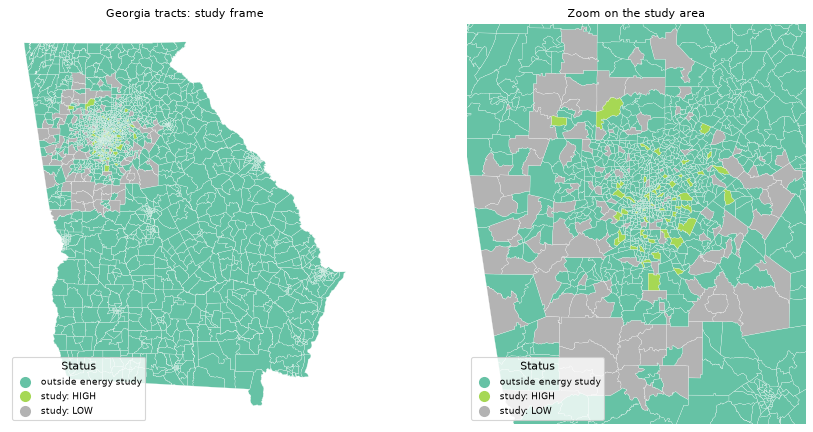

In [4]:
STUDY_WORKBOOKS = {"HIGH": ("highEE_FullData.xlsx", "Census Coordinates"), "LOW": ("lowEE_FullData.xlsx", "testCoordinates")}
CENSUS_RENAME = {"RFnewCensus_RF": "pred_RF_train_kwh", "RFnewCensus_cv": "pred_RF_cv_kwh", "matlabnewCens": "pred_MATLAB_kwh"}

frames = []
for label, (fname, coord_sheet) in STUDY_WORKBOOKS.items():
    coords = pd.read_excel(RAW_TABLES / fname, sheet_name=coord_sheet)
    est = pd.read_excel(RAW_TABLES / fname, sheet_name="censusEstimates")
    assert len(coords) == len(est) and list(est.columns) == list(CENSUS_RENAME), "estimates are not row-aligned with the coordinates"
    frames.append(pd.DataFrame({"GEOID10": coords["Census"].astype("int64").astype(str).str.zfill(11), "cluster": label,
                                "lat": coords["lat"], "lon": coords["lon"]}).join(est.rename(columns=CENSUS_RENAME)))
    print(f"{fname}: {len(coords)} tracts")
workbook_rows = pd.concat(frames, ignore_index=True)

both = workbook_rows[workbook_rows["GEOID10"].duplicated(keep=False)]
print(f"tracts in both workbooks: {sorted(both['GEOID10'].unique())}")
display(both)
study = workbook_rows.drop_duplicates("GEOID10", keep="first")  # HIGH rows come first
assert study["GEOID10"].is_unique and study.notna().all().all()
print(f"study tracts: {len(study)} ({study['cluster'].value_counts().to_dict()})")
assert study["cluster"].value_counts().to_dict() == {"LOW": 124, "HIGH": 50}

assert study["GEOID10"].isin(tract_gdf["GEOID10"]).all(), "a study tract is missing from the tract layer"
STATUS = ["study: HIGH", "study: LOW", "outside energy study"]
tract_status = tract_gdf.assign(study_status=pd.Categorical(
    tract_gdf["GEOID10"].map(study.set_index("GEOID10")["cluster"]).map({"HIGH": STATUS[0], "LOW": STATUS[1]}).fillna(STATUS[2]),
    categories=STATUS, ordered=True))
display(tract_status["study_status"].value_counts().rename("tracts").to_frame())

tract_gdf = tract_gdf.merge(study, on="GEOID10", how="inner", validate="one_to_one").sort_values("GEOID10").reset_index(drop=True)
assert len(tract_gdf) == len(study)

fig, axes = plt.subplots(1, 2, figsize=(12, 5.5))
for ax, title in zip(axes, ["Georgia tracts: study frame", "Zoom on the study area"]):
    plot_choropleth(tract_status, "study_status", title, ax=ax, cmap="Set2", legend_label="Status")
minx, miny, maxx, maxy = tract_gdf.total_bounds
axes[1].set(xlim=(minx - 5000, maxx + 5000), ylim=(miny - 5000, maxy + 5000))
fig.tight_layout()
plt.show()

### 3b. Estimate columns, `matlab_negative`, `energy_actual_kwh` and `pop`

| Workbook column | Column | Meaning |
|---|---|---|
| `RFnewCensus_RF` | `pred_RF_train_kwh` | Random forest, training-set fit |
| `RFnewCensus_cv` | `pred_RF_cv_kwh` | Random forest, cross-validated |
| `matlabnewCens` | `pred_MATLAB_kwh` | MATLAB regression (unreliable) |
| (new) | `matlab_negative` | `pred_MATLAB_kwh < 0` |
| (none) | `energy_actual_kwh` | NaN: observed residential energy is available only at ZIP level |
| `se_v001` of the socioeconomic table | `pop` | Total population |

The prediction names are the same as in the ZIP table. The renames were applied in Section 3a.

- **MATLAB estimates are known to be unreliable.** A negative energy estimate is physically meaningless. The
  column is kept and the negative tracts are flagged with `matlab_negative` rather than dropped.
- **Observed energy does not exist at tract level.** The socioeconomic source holds a residential-energy
  column for tracts, but it is 0 for every tract (a placeholder), which the code asserts. `energy_actual_kwh`
  is set to NaN so that no analysis mistakes the zeros for data.
- **`pop`** is `se_v001`, the total population of the socioeconomic table, as in the ZIP table, where the two
  are equal. The table is read here, and joined in full in Section 8.

In [5]:
PRED_COLS = list(CENSUS_RENAME.values())
tract_gdf["matlab_negative"] = tract_gdf["pred_MATLAB_kwh"] < 0
tract_gdf["energy_actual_kwh"] = np.nan  # no observed tract energy; see the note above

se_tract = pd.read_csv(INTERIM / "socioeconomic_tract.csv", dtype={"TractGeoID": str}).set_index("TractGeoID")
codebook = pd.read_csv(INTERIM / "socioeconomic_codebook.csv")
assert se_tract.index.is_unique and (se_tract.index.str.len() == 11).all()
assert (se_tract["se_resid_energy_kwh"] == 0).all(), "source tract energy is expected to be a 0 placeholder"
print(f"socioeconomic tract table: {len(se_tract)} tracts; se_resid_energy_kwh is 0 for all of them")

assert codebook.loc[1, "label_raw"] == "Number; SEX AND AGE - Total population"
assert tract_gdf["GEOID10"].isin(se_tract.index).all(), "a study tract is missing from the socioeconomic table"
tract_gdf["pop"] = tract_gdf["GEOID10"].map(se_tract["se_v001"])
assert tract_gdf["pop"].notna().all()
print(f"MATLAB estimates < 0: {tract_gdf['matlab_negative'].sum()} of {len(tract_gdf)} "
      f"({tract_gdf.groupby('cluster')['matlab_negative'].sum().to_dict()} by cluster)")

socioeconomic tract table: 1969 tracts; se_resid_energy_kwh is 0 for all of them
MATLAB estimates < 0: 75 of 174 ({'HIGH': 0, 'LOW': 75} by cluster)


### 3c. Join key `TractGeoID` and tract area `tract_area_sqft`

**`TractGeoID`** is `GEOID10` as a zero-padded **11-character string** (state + county + tract). Text keys
avoid the numeric-key join failures of the ArcGIS workflow (methodology §9).

**`tract_area_sqft`** is the planar polygon area in EPSG:2240. It is the **denominator of every area
metric**, so numerator and denominator always come from the same CRS.
- `ALAND10` is not used: it is in square metres and covers land only.
- ArcGIS's `Shape_Area` is not carried, because it would go stale if the geometry were edited.

The table below compares `tract_area_sqft` with `ALAND10 + AWATER10`.

The columns are then put in table order: the TIGER fields first, then `pop`, `lat`, `lon`, the three
predictions, `energy_actual_kwh`, `cluster` and `matlab_negative`, then the key and the area.

In [6]:
tract_gdf["TractGeoID"] = tract_gdf["GEOID10"]
tract_gdf["tract_area_sqft"] = tract_gdf.area
assert tract_gdf["TractGeoID"].is_unique and (tract_gdf["TractGeoID"].str.len() == 11).all()

BASE_ORDER = [*BASE_COLUMN_DOCS["column"], "pop", "lat", "lon", *PRED_COLS, "energy_actual_kwh", "cluster", "matlab_negative",
              "TractGeoID", "tract_area_sqft"]
tract_gdf = tract_gdf[[*BASE_ORDER, "geometry"]]

SQFT_PER_SQM = 10.763910417
pd.DataFrame({
    "tract_area_sqft / (ALAND10+AWATER10 in sq ft)": tract_gdf["tract_area_sqft"] / ((tract_gdf["ALAND10"] + tract_gdf["AWATER10"]) * SQFT_PER_SQM),
}).describe().T

,count,mean,std,min,25%,50%,75%,max
tract_area_sqft / (ALAND10+AWATER10 in sq ft),174.0,0.99984,0.000059,0.999796,0.999801,0.999814,0.999858,1.000065


### 3d. EDA and sanity check

The base layer must have one row per study tract (unique `TractGeoID`), complete predictions, an all-NaN
`energy_actual_kwh` and positive areas. It is saved as `data/interim/tract_base.gpkg` before any join.

Observed energy does not exist at tract level, so the scatter plots compare the models with each other:
RF cross-validated and MATLAB against the RF training fit, with the 1:1 line.

,n,n_null,pct_null,min,p25,median,p75,max,n_zero,n_negative
pred_RF_train_kwh,174,0,0.0,4.848692e+06,9.095424e+06,1.345479e+07,1.412515e+08,1.790997e+08,0,0
pred_RF_cv_kwh,174,0,0.0,4.648468e+06,8.003479e+06,1.148617e+07,1.438902e+08,1.736471e+08,0,0
pred_MATLAB_kwh,174,0,0.0,-7.658842e+06,-1.238133e+06,3.552946e+05,4.700493e+07,1.769923e+08,0,75
pop,174,0,0.0,1.311000e+03,4.764000e+03,6.260000e+03,7.923000e+03,2.065500e+04,0,0
tract_area_sqft,174,0,0.0,1.119546e+07,8.174080e+07,2.753782e+08,1.210568e+09,6.627679e+09,0,0


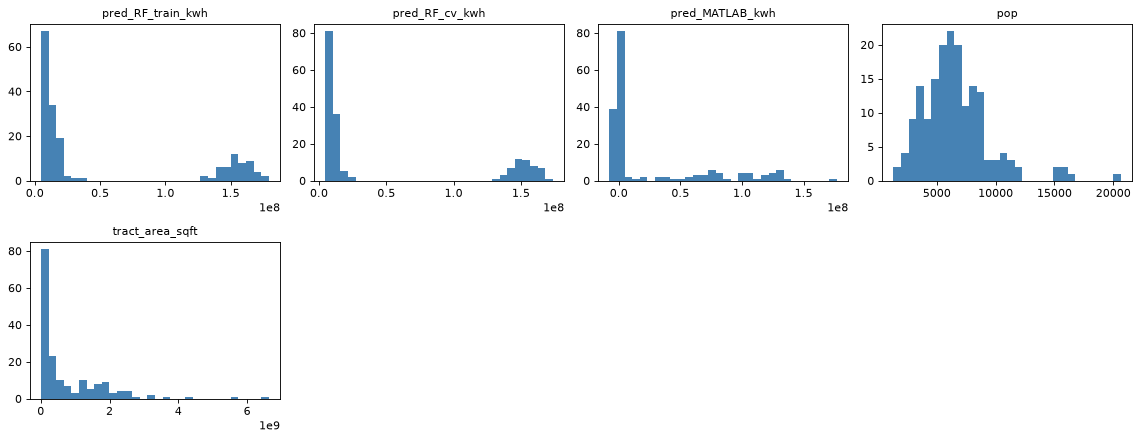

{'LOW': 124, 'HIGH': 50} ; matlab_negative: 75


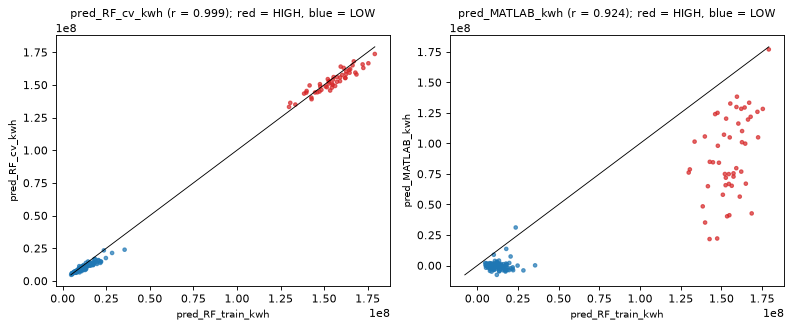

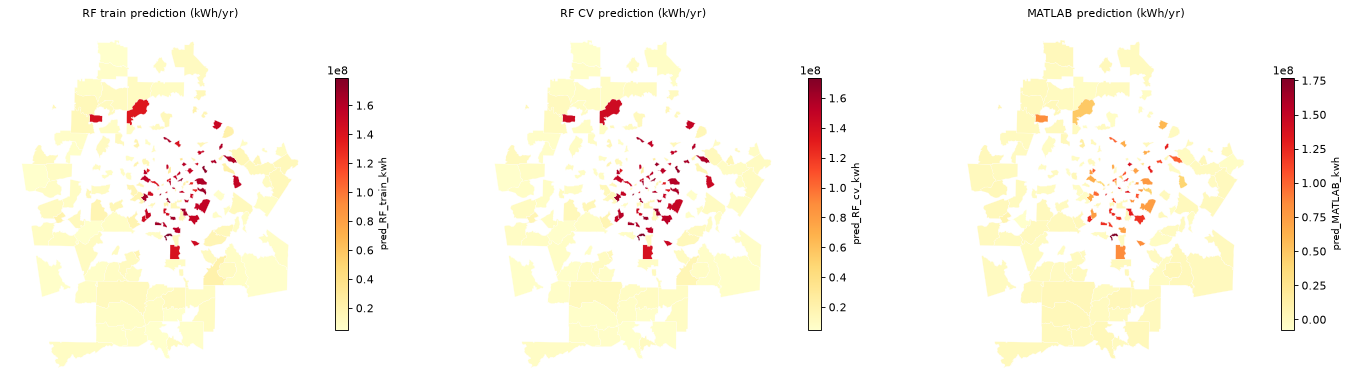

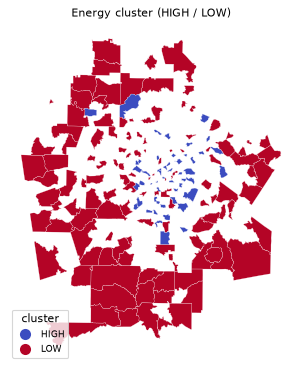

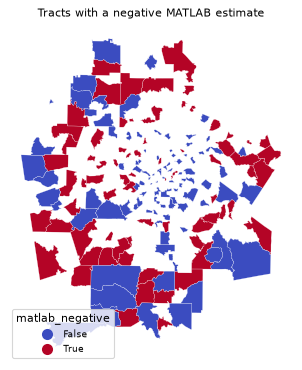

In [7]:
sanity_report(tract_gdf, PRED_COLS + ["pop", "tract_area_sqft"])
assert tract_gdf[PRED_COLS].notna().all().all() and tract_gdf["energy_actual_kwh"].isna().all()
assert (tract_gdf["tract_area_sqft"] > 0).all() and (tract_gdf["pop"] > 0).all()
print(tract_gdf["cluster"].value_counts().to_dict(), f"; matlab_negative: {tract_gdf['matlab_negative'].sum()}")

# Model against model, one panel per comparison, with the 1:1 line.
colors = tract_gdf["cluster"].map({"HIGH": "tab:red", "LOW": "tab:blue"})
fig, axes = plt.subplots(1, 2, figsize=(10, 4.2))
for ax, col in zip(axes, PRED_COLS[1:]):
    x = tract_gdf[["pred_RF_train_kwh", col]]
    ax.scatter(x["pred_RF_train_kwh"], x[col], s=10, c=colors, alpha=0.7)
    lim = [x.min().min(), x.max().max()]
    ax.plot(lim, lim, color="black", linewidth=0.8)
    r = np.corrcoef(x["pred_RF_train_kwh"], x[col])[0, 1]
    ax.set(xlabel="pred_RF_train_kwh", ylabel=col, title=f"{col} (r = {r:.3f}); red = HIGH, blue = LOW")
fig.tight_layout()
plt.show()

plot_choropleths(tract_gdf, PRED_COLS, ["RF train prediction (kWh/yr)", "RF CV prediction (kWh/yr)", "MATLAB prediction (kWh/yr)"],
                 ncols=3, cmap="YlOrRd")
plot_choropleth(tract_gdf, "cluster", "Energy cluster (HIGH / LOW)", cmap="coolwarm", legend_label="cluster")
plt.show()
plot_choropleth(tract_gdf, "matlab_negative", "Tracts with a negative MATLAB estimate", cmap="coolwarm", legend_label="matlab_negative")
plt.show()

tract_gdf.to_file(INTERIM / "tract_base.gpkg", driver="GPKG")

## 4. Distance to the CBD

**Data.** `cbd_atlanta.gpkg`: one polygon of the Atlanta central business district, provided with the
study data (EPSG:4269).

**Method.** `Dist_CBD_mi` is the Euclidean distance from each tract's **representative point** to the
CBD's representative point, computed in feet and divided by 5,280.

- **Why a representative point.** It is guaranteed to lie inside its polygon, the same as ArcGIS
  *Feature To Point* with "Inside" (methodology §3). A true centroid can fall outside a concave or
  multi-part polygon, such as an irregular tract or the CBD itself.
- **Why Euclidean.** It follows monocentric-city conventions and is the project's documented choice
  (methodology §3).

**Caveats.**
- Straight-line distance ignores the road network.
- For a large tract, one point summarises a wide range of distances.
- The vintage of the CBD boundary is to be confirmed.

**Sanity check.** Every distance must be positive. The map should show a smooth gradient centred on
downtown Atlanta.

Dist_CBD_mi    174


,n,n_null,pct_null,min,p25,median,p75,max,n_zero,n_negative
Dist_CBD_mi,174,0,0.0,1.289765,13.811035,26.928795,41.045622,79.210585,0,0


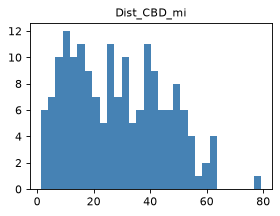

{'HIGH': 13.3, 'LOW': 35.5} (median mi by cluster)


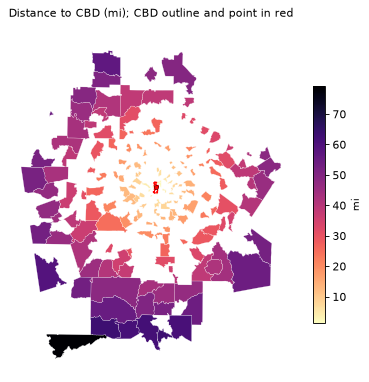

In [8]:
cbd_gdf = gpd.read_file(RAW_VECTORS / "cbd_atlanta.gpkg").to_crs(TARGET_CRS)
assert len(cbd_gdf) == 1
cbd_point = gpd.GeoDataFrame(geometry=cbd_gdf.representative_point(), crs=TARGET_CRS)

tract_points = tract_gdf[["TractGeoID", "geometry"]].assign(geometry=tract_gdf.representative_point())
tract_gdf = join_tract(tract_gdf, (tract_points.set_index("TractGeoID").distance(cbd_point.geometry.iloc[0]) / FT_PER_MI).rename("Dist_CBD_mi").to_frame())

sanity_report(tract_gdf, ["Dist_CBD_mi"])
assert (tract_gdf["Dist_CBD_mi"] > 0).all()
print(tract_gdf.groupby("cluster")["Dist_CBD_mi"].median().round(1).to_dict(), "(median mi by cluster)")

ax = plot_choropleth(tract_gdf, "Dist_CBD_mi", "Distance to CBD (mi); CBD outline and point in red",
                     cmap="magma_r", overlay=cbd_point, legend_label="mi")
cbd_gdf.boundary.plot(ax=ax, color="red", linewidth=1)
plt.show()

## 5. MARTA rail stations

**Data.** Layer `marta_rail_stations` of `MARTA_railstations_2025_georgia_zipcode.gpkg`: 38 MARTA
heavy-rail stations (field `STATION`), 2025, EPSG:3857.

**Method.** Two complementary measures of rail access:
- **Stations within each tract.** A point-in-polygon join (`predicate="within"`) gives
  `MARTA_stations_in_tract` and the flag `has_MARTA_station`. Tracts without a station get **0**, not NaN,
  because a missing station is a real zero.
- **Nearest-station distance.** `sjoin_nearest` from each tract's representative point gives
  `Dist_MARTA_Rail_mi` and `Nearest_MARTA_Station`. It is measured from the point, not the polygon:
  a distance to a polygon is 0 whenever a station lies inside it, which is how the first ArcGIS attempt
  failed (methodology §4).

**Caveats.**
- The station locations are from 2025, while the energy data is c. 2011. The heavy-rail network has
  not changed since the North Springs extension opened in 2000, so this does not matter for rail.
- Bus service is not included: it is outside the scope of this study.
- The count depends on tract size, so the flag and the distance are the more comparable measures.

**Sanity check.**
- The counts must sum to at most 38.
- Every distance must be positive.
- Stations outside every study tract must lie in tracts outside the energy study, not in gaps between
  polygons.

In [9]:
marta_gdf = gpd.read_file(RAW_VECTORS / "MARTA_railstations_2025_georgia_zipcode.gpkg", layer="marta_rail_stations").to_crs(TARGET_CRS)
assert len(marta_gdf) == 38

stations_in = gpd.sjoin(marta_gdf[["STATION", "geometry"]], tract_gdf[["TractGeoID", "geometry"]], predicate="within")
tract_gdf["MARTA_stations_in_tract"] = tract_gdf["TractGeoID"].map(stations_in["TractGeoID"].value_counts()).fillna(0).astype(int)
tract_gdf["has_MARTA_station"] = tract_gdf["MARTA_stations_in_tract"] > 0
print(f"stations in study tracts: {tract_gdf['MARTA_stations_in_tract'].sum()} of 38; "
      f"tracts with at least one: {tract_gdf['has_MARTA_station'].sum()} of {len(tract_gdf)}")

outside = gpd.sjoin(marta_gdf.drop(stations_in.index)[["STATION", "geometry"]],
                    tract_status[["GEOID10", "study_status", "geometry"]], how="left", predicate="within")
display(outside[["STATION", "GEOID10", "study_status"]])
assert outside["GEOID10"].notna().all(), "a station falls in no tract at all"

nearest = gpd.sjoin_nearest(tract_points, marta_gdf[["STATION", "geometry"]], distance_col="dist_ft").drop_duplicates("TractGeoID").set_index("TractGeoID")
tract_gdf = join_tract(tract_gdf, pd.DataFrame({"Dist_MARTA_Rail_mi": nearest["dist_ft"] / FT_PER_MI,
                                                "Nearest_MARTA_Station": nearest["STATION"]}))

stations in study tracts: 0 of 38; tracts with at least one: 0 of 174


,STATION,GEOID10,study_status
0,Decatur,13089022600,outside energy study
1,Avondale,13089022600,outside energy study
2,Chamblee,13089021204,outside energy study
3,Lakewood-Ft. McPherson,13121006601,outside energy study
4,Oakland City,13121006601,outside energy study
5,West End,13121004200,outside energy study
6,Arts Center,13121000400,outside energy study
7,Lindbergh Center,13121009402,outside energy study
8,Kensington,13089023113,outside energy study
9,Georgia State,13121003500,outside energy study


Dist_MARTA_Rail_mi       174
Nearest_MARTA_Station    174


,n,n_null,pct_null,min,p25,median,p75,max,n_zero,n_negative
MARTA_stations_in_tract,174,0,0.0,0.000000,0.000000,0.000000,0.000000,0.00000,174,0
Dist_MARTA_Rail_mi,174,0,0.0,0.565629,6.836434,20.061547,33.273325,69.16547,0,0


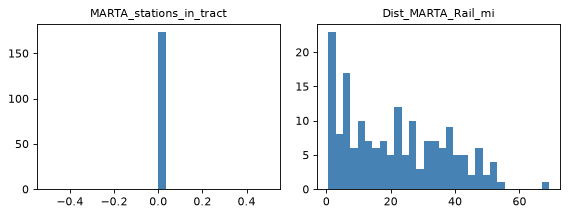

,count,mean,std,min,25%,50%,75%,max
has_MARTA_station,,,,,,,,
False,174.0,21.403172,15.649499,0.565629,6.836434,20.061547,33.273325,69.16547


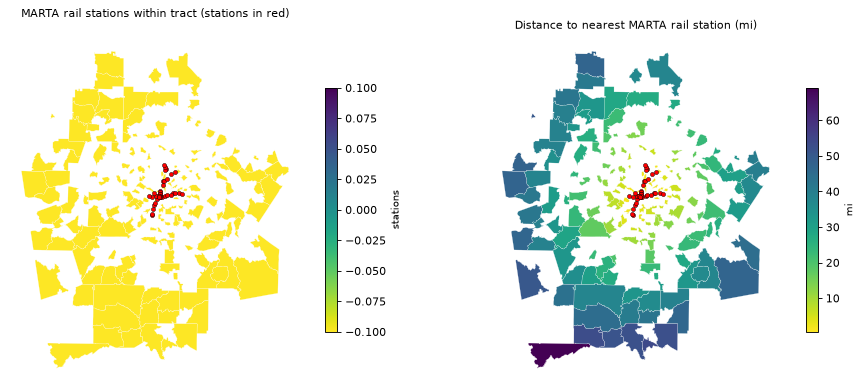

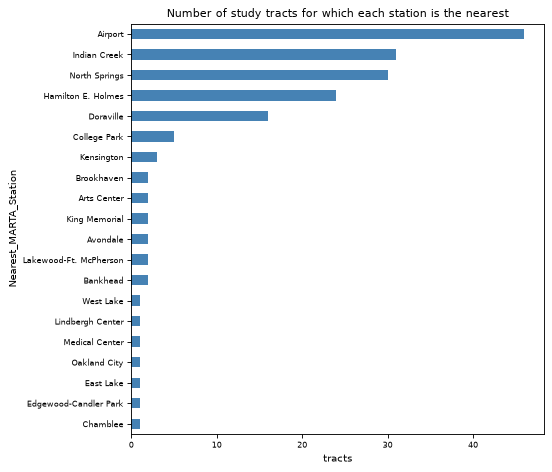

In [10]:
sanity_report(tract_gdf, ["MARTA_stations_in_tract", "Dist_MARTA_Rail_mi"])
assert tract_gdf["MARTA_stations_in_tract"].sum() <= 38 and (tract_gdf["Dist_MARTA_Rail_mi"] > 0).all()
display(tract_gdf.groupby("has_MARTA_station")["Dist_MARTA_Rail_mi"].describe())

plot_choropleths(tract_gdf, ["MARTA_stations_in_tract", "Dist_MARTA_Rail_mi"],
                 ["MARTA rail stations within tract (stations in red)", "Distance to nearest MARTA rail station (mi)"],
                 legend_labels=["stations", "mi"], overlay=marta_gdf, cmap="viridis_r")

ax = tract_gdf["Nearest_MARTA_Station"].value_counts().sort_values().plot.barh(figsize=(7, 6), color="steelblue", fontsize=7)
ax.set(title="Number of study tracts for which each station is the nearest", xlabel="tracts")
plt.tight_layout()
plt.show()

## 6. Walkability (EPA National Walkability Index v3.0)

**Data.** `EPA_walkabilityindex_2025_georgia_blockgroup.gpkg`: the EPA National Walkability Index v3.0
for every Georgia block group (EPSG:2240). Two variables are used:
- `NatWalkInd`: the walkability index, from 1 (least walkable) to 20.
- `D3B`: pedestrian-oriented street intersections per square mile (methodology §5).

**Method.** Tracts and block groups are intersected (`gpd.overlay`), and each tract gets the
**area-weighted mean** of its pieces:

$$\bar{x}_t = \frac{\sum_{b} x_b \, A_{t \cap b}}{\sum_{b} A_{t \cap b}}$$

$A_{t \cap b}$ is the area (sq ft) of the part of block group $b$ that lies inside tract $t$. Block groups
nest inside tracts (a block group's GEOID starts with its tract's), so the overlay is mostly a one-to-many
split. It is used anyway, so that the tract table uses exactly the method of the ZIP table, where block groups
do not nest. Area weighting suits both variables: `D3B` is a density, and `NatWalkInd` is a spatial index, not a
per-person quantity.

**Caveats.**
- **`D4A` is excluded.** Its name collides with the full SLD's transit-distance field, and it carries a
  −99999 sentinel (methodology §5). Rail access is measured directly in Section 5.
- Area weighting assumes a value is uniform within its block group.
- NWI v3.0 is later than the c. 2011 energy data.

**Sanity check.**
- Block-group coverage of each tract should be ≈ 1. Any tract below 0.95 is flagged.
- Each tract mean must lie within the range of the block-group values.

block groups in Georgia: 5711, intersecting the study tracts: 1575
D4A == -99999 (sentinel) in these block groups: 1148


,n,n_null,pct_null,min,p25,median,p75,max,n_zero,n_negative
NatWalkInd,1575,0,0.0,1.333333,5.000000,7.166667,10.250000,19.000000,0,0
D3B,1575,0,0.0,0.524303,9.815299,30.127659,51.910579,954.493429,0,0
TotPop,1575,0,0.0,0.000000,1366.000000,2002.000000,2884.500000,12037.000000,2,0
CountHU,1575,0,0.0,0.000000,566.000000,789.000000,1127.000000,4073.000000,3,0


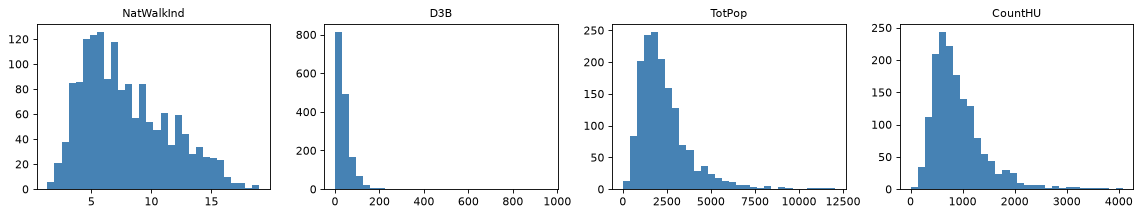

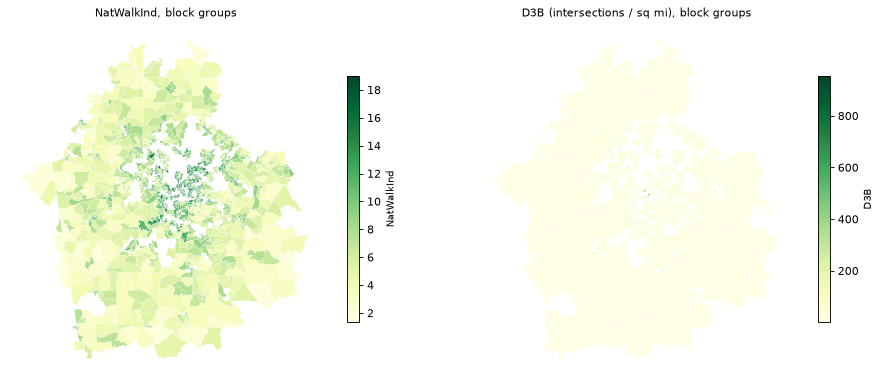

In [11]:
walkability_gdf = gpd.read_file(RAW_VECTORS / "EPA_walkabilityindex_2025_georgia_blockgroup.gpkg").to_crs(TARGET_CRS)
bg = walkability_gdf[walkability_gdf.intersects(tract_gdf.union_all())]
print(f"block groups in Georgia: {len(walkability_gdf)}, intersecting the study tracts: {len(bg)}")
print(f"D4A == -99999 (sentinel) in these block groups: {(bg['D4A'] == -99999).sum()}")

sanity_report(bg, ["NatWalkInd", "D3B", "TotPop", "CountHU"])
assert bg[["NatWalkInd", "D3B"]].notna().all().all() and (bg[["NatWalkInd", "D3B"]] >= 0).all().all()
plot_choropleths(bg, ["NatWalkInd", "D3B"], ["NatWalkInd, block groups", "D3B (intersections / sq mi), block groups"], cmap="YlGn")

NatWalkInd_tract    174
D3B_tract           174
block-group coverage of tract area: min 1.0000, max 1.0000; tracts < 0.95: 0


,n,n_null,pct_null,min,p25,median,p75,max,n_zero,n_negative
NatWalkInd_tract,174,0,0.0,2.666709,4.906718,6.412894,9.023239,19.000000,0,0
D3B_tract,174,0,0.0,0.966739,5.649250,19.282222,48.030181,207.935381,0,0


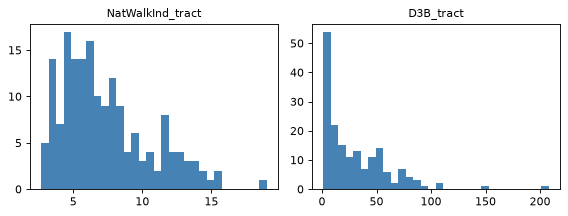

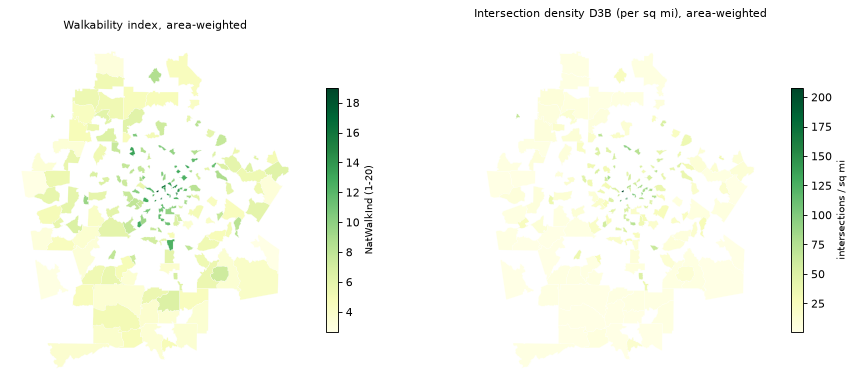

In [12]:
pieces = gpd.overlay(tract_gdf[["TractGeoID", "geometry"]], bg[["NatWalkInd", "D3B", "geometry"]], how="intersection", keep_geom_type=True)
pieces["w"] = pieces.area
sums = pieces.assign(NatWalkInd_tract=pieces["NatWalkInd"] * pieces["w"], D3B_tract=pieces["D3B"] * pieces["w"]).groupby("TractGeoID")
tract_gdf = join_tract(tract_gdf, sums[["NatWalkInd_tract", "D3B_tract"]].sum().div(sums["w"].sum(), axis=0))

coverage = sums["w"].sum() / tract_gdf.set_index("TractGeoID")["tract_area_sqft"]
print(f"block-group coverage of tract area: min {coverage.min():.4f}, max {coverage.max():.4f}; tracts < 0.95: {(coverage < 0.95).sum()}")

sanity_report(tract_gdf, ["NatWalkInd_tract", "D3B_tract"])
assert tract_gdf["NatWalkInd_tract"].between(1, 20).all() and tract_gdf["D3B_tract"].between(bg["D3B"].min(), bg["D3B"].max()).all()
plot_choropleths(tract_gdf, ["NatWalkInd_tract", "D3B_tract"],
                 ["Walkability index, area-weighted", "Intersection density D3B (per sq mi), area-weighted"],
                 legend_labels=["NatWalkInd (1-20)", "intersections / sq mi"], cmap="YlGn")

## 7. Microsoft building footprints

**Data.** `georgia_building_length_microsoft.gpkg`: Microsoft US Building Footprints for Georgia, about
4 million polygons in EPSG:4326. The file was converted from the ~1 GB GeoJSON with `ogr2ogr`
(methodology §2). The imagery dates from **2018–2020**.

**Method.**
- Footprint area is computed in sq ft (EPSG:2240).
- Each building is assigned to the tract containing its **representative point**, so a building on a tract
  boundary is counted exactly once. An *Intersects* join would count it in both tracts.
- Buildings are first cut to the study bounding box (`.cx`), to avoid a point-in-polygon test on all
  4 million.

**Outputs.**
- `ms_bldg_count`
- `ms_sum_area_sqft`, `ms_mean_area_sqft`, `ms_max_area_sqft`
- `ms_bldg_coverage_ratio` = `ms_sum_area_sqft` / `tract_area_sqft`

**Caveats.**
- **Vintage.** An ArcGIS QC against the 2012 City of Atlanta footprints found Microsoft's tract totals a
  median **+13.7%** higher (IQR +3.5% to +27.5%; methodology §2). Treat these metrics as slightly inflated
  relative to 2011.
- Footprints are 2-D outlines. They record neither height nor use.
- The coverage denominator includes water.
- Very small (< 100 sq ft) and very large (> 500,000 sq ft) footprints are counted but kept, because
  they are real features of the published product.

**Sanity check.** Every tract should have buildings, and every coverage ratio must lie strictly between 0
and 1.

buildings in Georgia: 3,981,792; in the study bounding box: 2,277,166; assigned to a study tract: 480,997 (21.1%)
tiny footprints (< 100 sq ft): 14; huge footprints (> 500,000 sq ft): 42


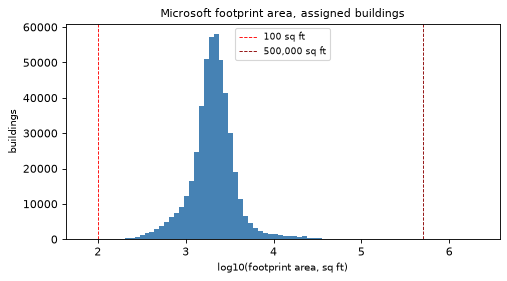

In [13]:
ms_buildings_gdf = gpd.read_file(RAW_VECTORS / "georgia_building_length_microsoft.gpkg").to_crs(TARGET_CRS)
minx, miny, maxx, maxy = tract_gdf.total_bounds
bldg = ms_buildings_gdf.cx[minx:maxx, miny:maxy][["geometry"]]
bldg = gpd.GeoDataFrame({"bldg_area_sqft": bldg.area}, geometry=bldg.representative_point(), crs=TARGET_CRS)
n_bbox = len(bldg)
bldg = gpd.sjoin(bldg, tract_gdf[["TractGeoID", "geometry"]], predicate="within")
print(f"buildings in Georgia: {len(ms_buildings_gdf):,}; in the study bounding box: {n_bbox:,}; "
      f"assigned to a study tract: {len(bldg):,} ({len(bldg) / n_bbox:.1%})")

area = bldg["bldg_area_sqft"]
print(f"tiny footprints (< 100 sq ft): {(area < 100).sum():,}; huge footprints (> 500,000 sq ft): {(area > 500_000).sum():,}")
fig, ax = plt.subplots(figsize=(7, 3.5))
ax.hist(np.log10(area), bins=80, color="steelblue")
for v, c in [(100, "red"), (500_000, "darkred")]:
    ax.axvline(np.log10(v), color=c, linestyle="--", linewidth=0.8, label=f"{v:,} sq ft")
ax.set(title="Microsoft footprint area, assigned buildings", xlabel="log10(footprint area, sq ft)", ylabel="buildings")
ax.legend(fontsize=8)
plt.show()

ms_bldg_count             174
ms_sum_area_sqft          174
ms_mean_area_sqft         174
ms_max_area_sqft          174
ms_bldg_coverage_ratio    174


,n,n_null,pct_null,min,p25,median,p75,max,n_zero,n_negative
ms_bldg_count,174,0,0.0,5.130000e+02,1.761000e+03,2.553000e+03,3.581750e+03,8.018000e+03,0,0
ms_sum_area_sqft,174,0,0.0,1.659467e+06,4.892321e+06,7.136974e+06,1.036698e+07,3.508000e+07,0,0
ms_mean_area_sqft,174,0,0.0,1.736549e+03,2.389699e+03,2.660063e+03,3.147346e+03,1.138770e+04,0,0
ms_max_area_sqft,174,0,0.0,1.849383e+04,9.831395e+04,1.716927e+05,2.580931e+05,2.232392e+06,0,0
ms_bldg_coverage_ratio,174,0,0.0,1.248893e-03,8.112103e-03,3.564423e-02,7.779907e-02,2.543364e-01,0,0


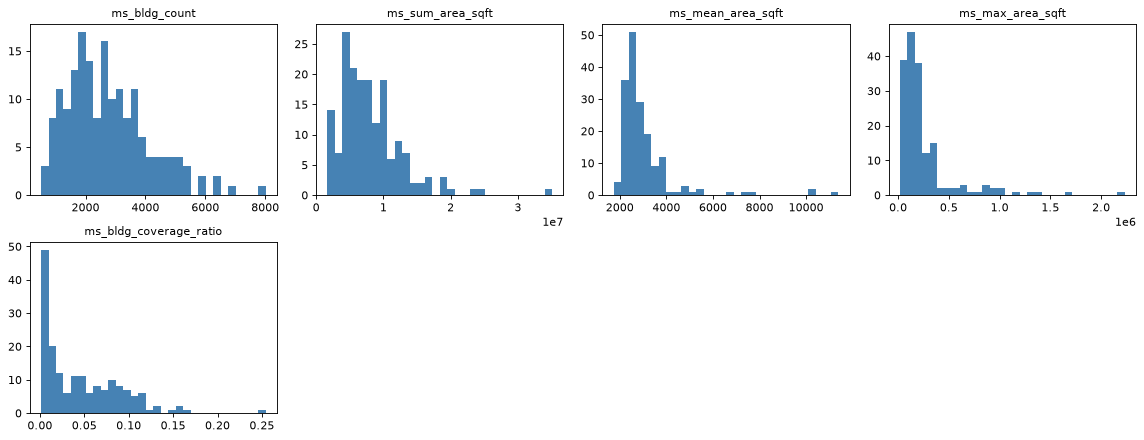

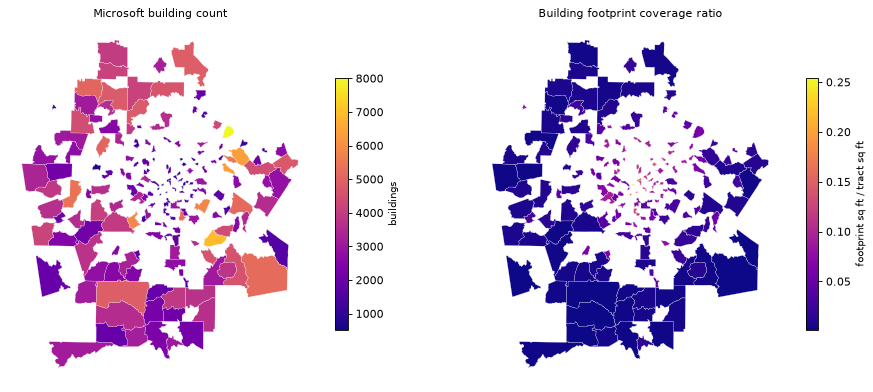

In [14]:
bldg_vars = bldg.groupby("TractGeoID")["bldg_area_sqft"].agg(
    ms_bldg_count="count", ms_sum_area_sqft="sum", ms_mean_area_sqft="mean", ms_max_area_sqft="max")
bldg_vars["ms_bldg_coverage_ratio"] = bldg_vars["ms_sum_area_sqft"] / tract_gdf.set_index("TractGeoID")["tract_area_sqft"]
MS_COLS = list(bldg_vars.columns)
tract_gdf = join_tract(tract_gdf, bldg_vars)

sanity_report(tract_gdf, MS_COLS)
assert tract_gdf[MS_COLS].notna().all().all() and tract_gdf["ms_bldg_coverage_ratio"].between(0, 1, inclusive="neither").all()
plot_choropleths(tract_gdf, ["ms_bldg_count", "ms_bldg_coverage_ratio"], ["Microsoft building count", "Building footprint coverage ratio"],
                 legend_labels=["buildings", "footprint sq ft / tract sq ft"], cmap="plasma")

## 8. Socioeconomic variables (2011 ACS/Census, tract level)

### 8.1 Data

The source is the tract table that notebook 01 (Section 8) cleaned from `May_Zip_Tract_regular_June_2.xlsx`
and saved as `data/interim/socioeconomic_tract.csv`. It is **not re-parsed here**. It holds one row for each
of the 1,969 Georgia Census tracts, keyed `TractGeoID` (text, 11 characters), with:
- `se_resid_energy_kwh`: the workbook's residential-energy column, which is **0 for every tract** (a
  placeholder; Section 3b);
- `se_v001` … `se_v356`: the 356 ACS/Census variables and derived ratios.

The codebook, `data/interim/socioeconomic_codebook.csv`, was read in Section 3b. Its labels and cluster-model
predictor flags are used below exactly as in notebook 01.

In [15]:
SE_COLS = list(codebook.loc[codebook["role"] == "variable", "se_code"])
assert list(se_tract.columns) == ["se_resid_energy_kwh", *SE_COLS]
pd.DataFrame({"tract rows": [len(se_tract)], "study tracts present": [tract_gdf["TractGeoID"].isin(se_tract.index).sum()],
              "variables": [len(SE_COLS)]}, index=["socioeconomic_tract.csv"])

,tract rows,study tracts present,variables
socioeconomic_tract.csv,1969,174,356


### 8.2 Codebook

- Each data column has a stable code: `se_v{number:03d}`, or `se_resid_energy_kwh` for column 0.
- Seven labels are duplicated in the source codebook. Each repeat has a ` [dup k]` suffix, so every label is
  unique.
- `in_highEE_model` / `in_lowEE_model` flag the predictors of each cluster model. The predictors are
  the column names of the `highET_Og` sheet in each model workbook, minus `Energy`, matched after
  normalising whitespace.

The flags are recomputed from the workbooks below and must equal the saved codebook's.

In [16]:
def norm_label(s):
    return re.sub(r"\s+", " ", str(s)).strip()


assert codebook["label"].is_unique and codebook["se_code"].is_unique
label_norm = codebook["label_raw"].map(norm_label)
MODEL_PREDICTORS = {}
for label, (fname, _) in STUDY_WORKBOOKS.items():
    preds = [c for c in pd.read_excel(RAW_TABLES / fname, sheet_name="highET_Og", nrows=0).columns if c != "Energy"]
    MODEL_PREDICTORS[label] = preds
    assert (codebook[f"in_{label.lower()}EE_model"] == label_norm.isin({norm_label(p) for p in preds})).all()
    print(f"{fname}: {len(preds)} predictors; unmatched labels: {[p for p in preds if norm_label(p) not in set(label_norm)]}")

display(codebook.loc[codebook["label_raw"].duplicated(keep=False), ["se_code", "label"]])

highEE_FullData.xlsx: 18 predictors; unmatched labels: []
lowEE_FullData.xlsx: 35 predictors; unmatched labels: []


,se_code,label
60,se_v060,Number; HOUSING OCCUPANCY - Total housing unit...
63,se_v063,Number; HOUSING OCCUPANCY - Total housing unit...
175,se_v175,Percent; INCOME AND BENEFITS (IN 2011 INFLATIO...
176,se_v176,Percent; INCOME AND BENEFITS (IN 2011 INFLATIO...
177,se_v177,Percent; INCOME AND BENEFITS (IN 2011 INFLATIO...
180,se_v180,Percent; INCOME AND BENEFITS (IN 2011 INFLATIO...
181,se_v181,Percent; INCOME AND BENEFITS (IN 2011 INFLATIO...
182,se_v182,Percent; INCOME AND BENEFITS (IN 2011 INFLATIO...
346,se_v346,"Estimate; INCOME AND BENEFITS (IN 2011-(dol, a..."
347,se_v347,"Estimate; INCOME AND BENEFITS (IN 2011-(dol, a..."


### 8.3 Cleaning rules

Notebook 01 turned every cell of the source into a number:

- **Placeholders → NaN:** `-`, `N`, `\` and `(X)` (ACS "no estimate" / "not applicable").
- **Censored values → their bound:** `1939-` and `2005+` (median year built), `2,000+` (rent) and
  similar. The trailing `+`/`-` and the thousands separators are stripped. The true value lies beyond
  the bound, so treat these as censored.
- **Anything else → NaN.** The 1,969 tract rows contain a few dozen annotated cells such as `710(r2968)`
  (48 in notebook 01's cleaning table). Their meaning is unknown.

The table below counts the NaN cells among the study tracts, by variable.

In [17]:
na_cells = se_tract.loc[tract_gdf["TractGeoID"], SE_COLS].isna()
print(f"NaN cells among the {len(na_cells)} study tracts: {na_cells.sum().sum()} of {na_cells.size:,}; "
      f"variables with at least one NaN: {(na_cells.sum() > 0).sum()}; "
      f"NaN cells in all {len(se_tract)} tract rows: {se_tract[SE_COLS].isna().sum().sum()}")
na_by_var = na_cells.sum()[lambda s: s > 0].sort_values(ascending=False).rename("study tracts with NaN").to_frame()
display(na_by_var.join(codebook.set_index("se_code")["label"]).head(15))

NaN cells among the 174 study tracts: 5 of 61,944; variables with at least one NaN: 3; NaN cells in all 1969 tract rows: 6038


,study tracts with NaN,label
se_v356,3,Binary representation of year built
se_v353,1,Area
se_v354,1,Population density [dup 2]


### 8.4 Alignment check

Before joining, the source must reproduce the base layer:

- all study tracts are present in the socioeconomic table;
- total population (`se_v001`) equals `pop`.

(`se_resid_energy_kwh` is a placeholder of zeros here, so there is no energy column to compare with. See
Section 3b.)

In [18]:
assert tract_gdf["TractGeoID"].isin(se_tract.index).all()
aligned = se_tract.loc[tract_gdf["TractGeoID"]]
assert codebook.loc[1, "label_raw"] == "Number; SEX AND AGE - Total population"
assert np.isclose(aligned["se_v001"], tract_gdf["pop"]).all()
print(f"alignment OK: {len(aligned)}/{len(tract_gdf)} tracts present; total population matches")

alignment OK: 174/174 tracts present; total population matches


### 8.5 Join

The join is a direct one-to-one match on `TractGeoID`. No aggregation is needed, because both tables are at
tract level. `se_resid_energy_kwh` is left out because it is a placeholder.

**EDA.**
- A missing-value count.
- Six key variables, mapped and summarised. They are looked up by codebook label, and each lookup must
  match.
- The predictors of each cluster model.

**Population density** appears twice in the codebook. The copy used here, `se_v354`, is the one that
equals total population / area (`se_v355` / `se_v353`, persons per sq mi) at ZIP level. **At tract level this
identity does not hold**: `se_v353` (Area) and `se_v354` do not agree with each other or with the TIGER tract
area (the code prints the numbers). The columns are kept as delivered, but `se_v353`, `se_v354` and
`se_v349` should not be used as tract area or density. Compute density from `se_v001` / `tract_area_sqft`.

**Caveats.**
- The source is a compilation of 2011 ACS/Census data. Whether it uses the 5-year or 1-year ACS is to
  be confirmed.
- Several variables are derived ratios whose formulas are known only from their labels.
- Tract estimates have wider margins of error than ZIP estimates, and some tract cells are NaN (Section 8.3).

SE variables joined: 356; tracts matched: 174/174; missing values among them: 5


se_v354 == se_v355 / se_v353 for 2 of 174 study tracts; Spearman of se_v353 (Area) with the TIGER tract area: 0.02; se_v354 vs population / TIGER area: -0.11


,se_code,label
Total population,se_v001,Number; SEX AND AGE - Total population
Median household income ($),se_v178,Estimate; INCOME AND BENEFITS (IN 2011 INFLATI...
Median home value ($),se_v161,Estimate; VALUE - Median (dollars)
Population density (persons / sq mi),se_v354,Population density [dup 2]
Median year structure built,se_v352,Estimate; Median year structure built
% commuting by public transit,se_v172,Percent; COMMUTING TO WORK - Public transporta...


,n,n_null,pct_null,min,p25,median,p75,max,n_zero,n_negative
se_v001,174,0,0.0,1311.000000,4764.00000,6260.00000,7923.000000,20655.000000,0,0
se_v178,174,0,0.0,15893.000000,42811.50000,53471.50000,65952.250000,135455.000000,0,0
se_v161,174,0,0.0,74900.000000,129625.00000,157450.00000,201375.000000,627600.000000,0,0
se_v354,173,1,0.6,0.916754,24.02129,24.02129,78.002853,13914.285714,0,0
se_v352,174,0,0.0,1941.000000,1978.00000,1987.00000,1993.000000,2002.000000,0,0
se_v172,174,0,0.0,0.000000,0.00000,0.70000,2.675000,31.500000,51,0


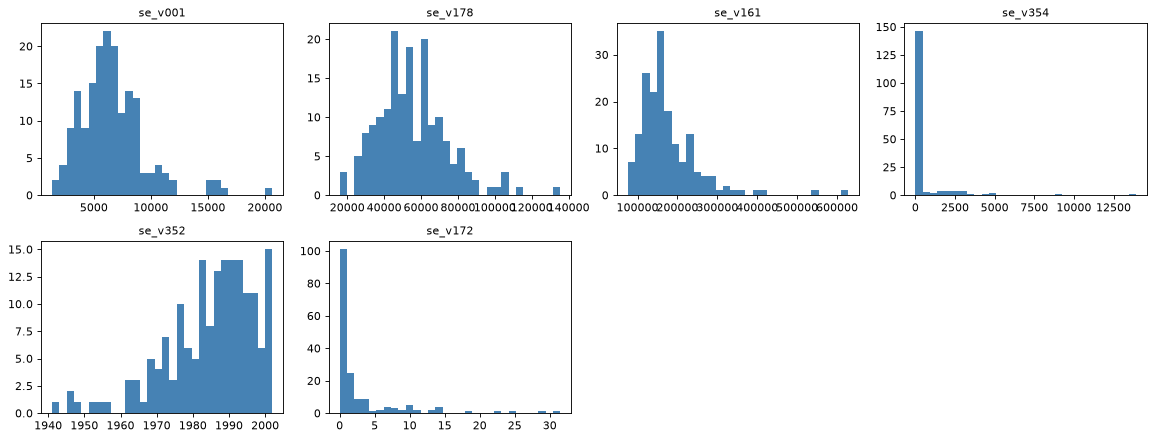

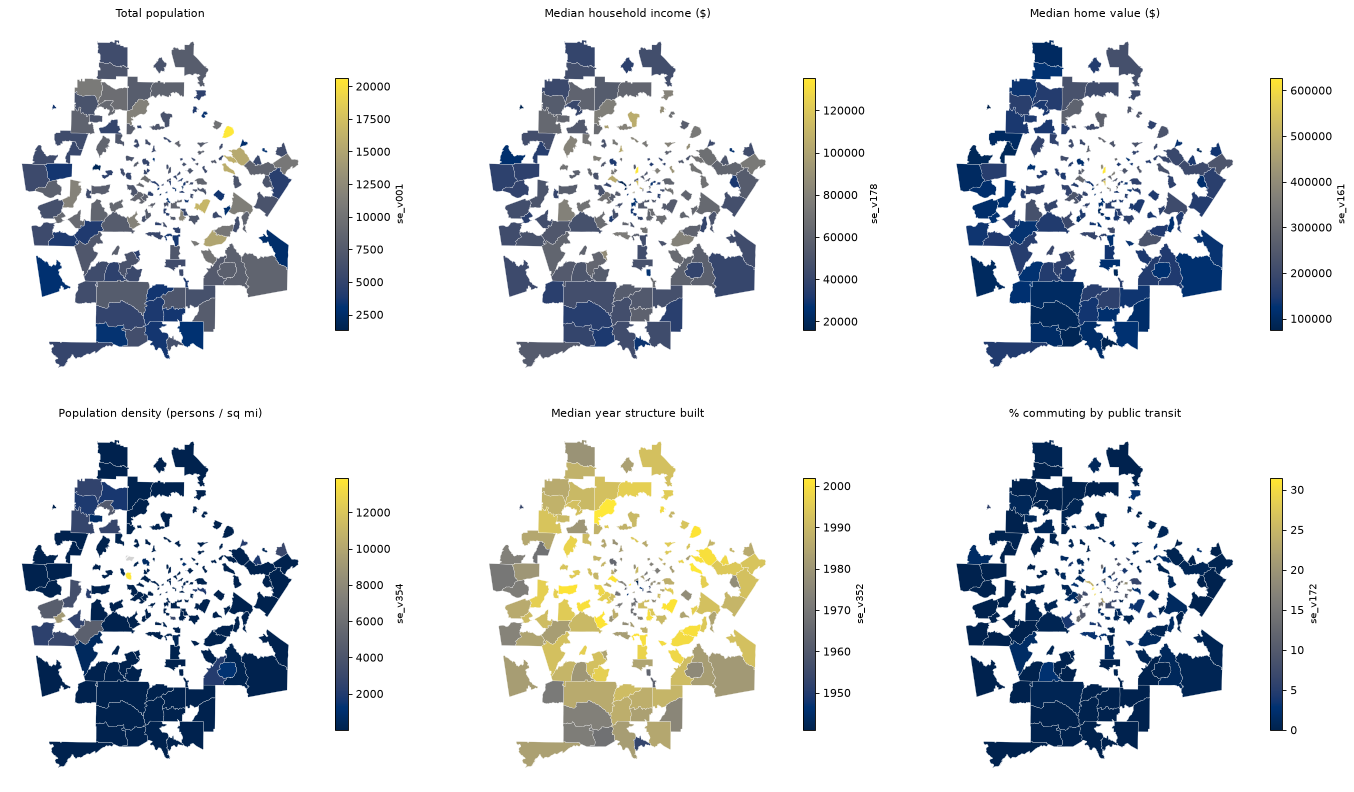

,model,predictor_label,se_code
0,HIGH cluster,Percent; EMPLOYMENT STATUS - All parents in family in labor force pop over 16,se_v169
1,HIGH cluster,Number; SEX AND AGE - Male population - 62 years and over,se_v014
2,HIGH cluster,Number; SEX AND AGE - Total population,se_v001
3,HIGH cluster,100*Number of rent occupied house units with >= 1 vehicle/Total rent occupied Housing units,se_v214
4,HIGH cluster,Pop 5 to 24,se_v002
5,HIGH cluster,100*White Occupied Owned Housing Units/Tot Number of Owned Occupied Housing Units,se_v072
6,HIGH cluster,Tot Female_Male Ratio High school Diploma,se_v307
7,HIGH cluster,Number; SEX AND AGE - Male population,se_v009
8,HIGH cluster,Number of Housing Units Built 1970 to 1979 or later/Total Housing Units,se_v275
9,HIGH cluster,100*Owner occupied: - 7-or-more-person household/Total Owner Ocuppied House units,se_v100


In [19]:
tract_gdf = tract_gdf.join(se_tract[SE_COLS], on="TractGeoID", validate="one_to_one")
n_matched = tract_gdf[SE_COLS].notna().any(axis=1).sum()
print(f"SE variables joined: {len(SE_COLS)}; tracts matched: {n_matched}/{len(tract_gdf)}; "
      f"missing values among them: {tract_gdf[SE_COLS].isna().sum().sum()}")
assert n_matched == len(tract_gdf)


def find_se(label, exact=False):
    """se_code of the first codebook variable whose label contains (or equals) `label`."""
    lab = codebook["label_raw"]
    hits = codebook[(lab == label if exact else lab.str.contains(label, regex=False)) & (codebook["role"] == "variable")]
    assert len(hits) > 0, f"no codebook label matches {label!r}"
    return hits["se_code"].iloc[0]


assert codebook.loc[354, "label_raw"] == "Population density"
# At ZIP level se_v354 == se_v355 / se_v353 (asserted in notebook 01). At tract level it is not: report instead of asserting.
n_density_ok = np.isclose(tract_gdf["se_v354"], tract_gdf["se_v355"] / tract_gdf["se_v353"], equal_nan=True).sum()
area_sqmi = tract_gdf["tract_area_sqft"] / 27_878_400
print(f"se_v354 == se_v355 / se_v353 for {n_density_ok} of {len(tract_gdf)} study tracts; "
      f"Spearman of se_v353 (Area) with the TIGER tract area: {tract_gdf['se_v353'].corr(area_sqmi, method='spearman'):.2f}; "
      f"se_v354 vs population / TIGER area: {tract_gdf['se_v354'].corr(tract_gdf['se_v355'] / area_sqmi, method='spearman'):.2f}")
KEY_SE = {
    "Total population": find_se("Number; SEX AND AGE - Total population", exact=True),
    "Median household income ($)": find_se("Median household income"),
    "Median home value ($)": find_se("VALUE - Median"),
    "Population density (persons / sq mi)": "se_v354",
    "Median year structure built": find_se("Median year structure built"),
    "% commuting by public transit": find_se("Public transportation"),
}
display(pd.DataFrame({"se_code": KEY_SE}).join(codebook.set_index("se_code")["label"], on="se_code"))

sanity_report(tract_gdf, list(KEY_SE.values()))
assert tract_gdf[KEY_SE["% commuting by public transit"]].between(0, 100).all()
assert tract_gdf[KEY_SE["Median year structure built"]].between(1939, 2011).all()
plot_choropleths(tract_gdf, list(KEY_SE.values()), list(KEY_SE.keys()), ncols=3, cmap="cividis")

code_of = dict(zip(label_norm[::-1], codebook["se_code"][::-1]))  # first match wins
with pd.option_context("display.max_colwidth", 120, "display.max_rows", 100):
    display(pd.DataFrame([(f"{k} cluster", p, code_of.get(norm_label(p))) for k, v in MODEL_PREDICTORS.items() for p in v],
                         columns=["model", "predictor_label", "se_code"]))

## 9. Land use (ARC LandPro 2012)

**Data.** `LandPro_2012.shp`: the Atlanta Regional Commission's 2012 land-use / land-cover polygons,
public open data. It has 54,162 polygons and is already in EPSG:2240. Two fields are used:
- `LU_NAME`: 29 land-use classes (e.g. `RES_LOW`, `COMMERCIAL`, `FOREST`, `IND/COM`);
- `DE3`: a three-way grouping of those classes into `DEVELOPED`, `UNDEVELOPED` and `UNDEVELOPABLE`.

**Method.**
- About 0.7% of the geometries are invalid (self-intersections). They are repaired with `make_valid()`,
  and only the polygonal parts are kept. Without the repair, the overlay fails with a
  `TopologyException`.
- Tracts and LandPro polygons are intersected (`gpd.overlay`), and the area of each piece is computed in
  sq ft.
- **`landpro_coverage_frac`** = LandPro area inside the tract / `tract_area_sqft`. It is kept for all
  study tracts.
- **`lu_pct_<class>`** is the share of each of the 29 `LU_NAME` classes, and **`lu_pct_developed`**,
  **`lu_pct_undeveloped`** and **`lu_pct_undevelopable`** the shares of the `DE3` groups, all as a
  **percent of the covered area**. Class names are lower-cased, and `/` becomes `_` (`IND/COM` →
  `lu_pct_ind_com`). A class absent from a tract gets 0.
- **Shares are set to NaN unless `landpro_coverage_frac` ≥ 0.99.** A share computed on a small covered
  fraction describes only the part of the tract inside the ARC region, not the tract, so it is withheld
  rather than extrapolated.

**Caveats.**
- **LandPro covers only the ARC region** (the metro counties). Tracts on the edge of the study area are
  partly or wholly outside it, so land-use analyses cover only part of the study tracts. The number of tracts
  by coverage band and cluster is tabulated below.
- The land-use classes are interpreted from 2012 imagery and parcel data. Class boundaries are
  approximate.
- `DE3` is almost, but not strictly, nested within `LU_NAME`: four small `CHURCH` / `COMMERCIAL`
  polygons carry a different group from the rest of their class (table below). The `DE3` shares are
  therefore computed from the `DE3` field itself.
- The covered area includes water (`RESERVOIRS`, `RIVERS`), like the other area denominators.

**Sanity check.**
- The 29 class shares, and the three `DE3` shares, must each sum to 100% (±0.5) for covered tracts.
- Coverage must not exceed 1 (tolerance 0.001). Coverage above 1 would reveal overlapping LandPro
  polygons.

In [20]:
landpro_gdf = gpd.read_file(RAW_VECTORS / "LandPro_2012.shp").to_crs(TARGET_CRS)
n_polygons, n_invalid = len(landpro_gdf), (~landpro_gdf.is_valid).sum()
display(landpro_gdf.groupby(["DE3", "LU_NAME"]).agg(polygons=("ACRES", "size"), acres=("ACRES", "sum")).round(0))

landpro_gdf["geometry"] = landpro_gdf.make_valid()
landpro_gdf = landpro_gdf.explode(index_parts=False)
landpro_gdf = landpro_gdf[landpro_gdf.geom_type == "Polygon"]
assert landpro_gdf.is_valid.all()
print(f"LandPro polygons: {n_polygons:,}; invalid, repaired with make_valid: {n_invalid} ({n_invalid / n_polygons:.1%}); "
      f"polygonal parts kept: {len(landpro_gdf):,}")

LU_CLASSES = sorted(landpro_gdf["LU_NAME"].unique())
DE3_GROUPS = ["DEVELOPED", "UNDEVELOPED", "UNDEVELOPABLE"]
assert len(LU_CLASSES) == 29 and set(landpro_gdf["DE3"]) == set(DE3_GROUPS)

polygons      acres
DE3           LU_NAME                            
DEVELOPED     AIRPORT               41     9080.0
              CHURCH              3770    20953.0
              COMMERCIAL          4190   135267.0
              CST                 1998    36297.0
              IND/COM              463    60687.0
              INDUSTRIAL           170     8228.0
              INST_INTENSIVE      1735    46599.0
              RES_HIGH            1989    72798.0
              RES_LOW             6941   574448.0
              RES_MED             4143   630568.0
              RES_MOBILE           302     7103.0
              RES_MULTI           2320    56558.0
              TCU                  270    11481.0
UNDEVELOPABLE CEMETERIES           945     5783.0
              CHURCH                 1        2.0
              COMMERCIAL             2        9.0
              EXPOSED_ROCK         119     1490.0
              GOLF_COURSES         370    29284.0
              INST_EXTENSIVE       760    46357.0
              LTD_ACCESS            14    23698.0
              PARKS                742    20486.0
              PARK_LAND           1236   146977.0
              QUARRIES              42     9691.0
              RESERVOIRS          2243    84260.0
              RIVERS                 6     4769.0
              WETLANDS            1299    85613.0
UNDEVELOPED   AGRICULTURE         4159   678602.0
              CHURCH                 1        4.0
              FOREST              9893  1319028.0
              LANDFILLS             59     7129.0
              TRANSITIONAL        3104    84250.0
              URBAN_OTHER          835    17449.0

LandPro polygons: 54,162; invalid, repaired with make_valid: 363 (0.7%); polygonal parts kept: 54,188


In [21]:
pieces = gpd.overlay(tract_gdf[["TractGeoID", "geometry"]], landpro_gdf[["LU_NAME", "DE3", "geometry"]], how="intersection", keep_geom_type=True)
pieces["w"] = pieces.area
lu_area = pieces.pivot_table(index="TractGeoID", columns="LU_NAME", values="w", aggfunc="sum", fill_value=0).reindex(columns=LU_CLASSES, fill_value=0)
de3_area = pieces.pivot_table(index="TractGeoID", columns="DE3", values="w", aggfunc="sum", fill_value=0).reindex(columns=DE3_GROUPS, fill_value=0)
covered = lu_area.sum(axis=1)

LU_DE3_COLS = ["lu_pct_" + g.lower() for g in DE3_GROUPS]
LU_CLASS_COLS = ["lu_pct_" + c.lower().replace("/", "_") for c in LU_CLASSES]
LU_COLS = LU_DE3_COLS + LU_CLASS_COLS
assert all(re.fullmatch(r"[a-z0-9_]+", c) for c in LU_COLS)

tract_area = tract_gdf.set_index("TractGeoID")["tract_area_sqft"]
landuse = pd.concat([de3_area.set_axis(LU_DE3_COLS, axis=1), lu_area.set_axis(LU_CLASS_COLS, axis=1)], axis=1).div(covered, axis=0) * 100
landuse.insert(0, "landpro_coverage_frac", covered / tract_area)
landuse = landuse.reindex(tract_area.index)
landuse["landpro_coverage_frac"] = landuse["landpro_coverage_frac"].fillna(0)
landuse.loc[landuse["landpro_coverage_frac"] < 0.99, LU_COLS] = np.nan
tract_gdf = join_tract(tract_gdf, landuse)

landpro_coverage_frac    174
lu_pct_developed         142
lu_pct_undeveloped       142
lu_pct_undevelopable     142
lu_pct_agriculture       142
lu_pct_airport           142
lu_pct_cemeteries        142
lu_pct_church            142
lu_pct_commercial        142
lu_pct_cst               142
lu_pct_exposed_rock      142
lu_pct_forest            142
lu_pct_golf_courses      142
lu_pct_ind_com           142
lu_pct_industrial        142
lu_pct_inst_extensive    142
lu_pct_inst_intensive    142
lu_pct_landfills         142
lu_pct_ltd_access        142
lu_pct_parks             142
lu_pct_park_land         142
lu_pct_quarries          142
lu_pct_reservoirs        142
lu_pct_res_high          142
lu_pct_res_low           142
lu_pct_res_med           142
lu_pct_res_mobile        142
lu_pct_res_multi         142
lu_pct_rivers            142
lu_pct_tcu               142
lu_pct_transitional      142
lu_pct_urban_other       142
lu_pct_wetlands          142


cluster,HIGH,LOW,All
LandPro coverage,,,
>= 0.99 (shares kept),50,92,142
0 to 0.5,0,14,14
0 (outside ARC region),0,18,18
All,50,124,174


tracts with LandPro coverage >= 0.99: 142 of 174
max coverage: 1.000000; tracts with coverage > 1.0001 (overlapping LandPro polygons): 0


,n,n_null,pct_null,min,p25,median,p75,max,n_zero,n_negative
landpro_coverage_frac,174,0,0.0,0.000000,0.999983,1.000000,1.000000,1.000000,18,0
lu_pct_developed,142,32,18.4,5.387372,33.206054,57.829550,84.801439,100.000000,0,0
lu_pct_undeveloped,142,32,18.4,0.000000,6.970911,31.746145,57.116536,91.226801,4,0
lu_pct_undevelopable,142,32,18.4,0.000000,4.059702,6.863324,12.683110,53.423032,2,0


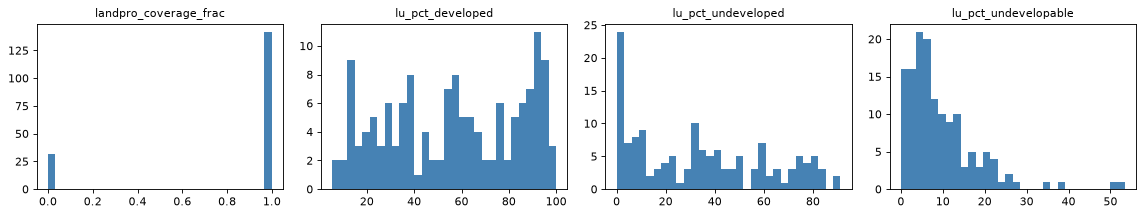

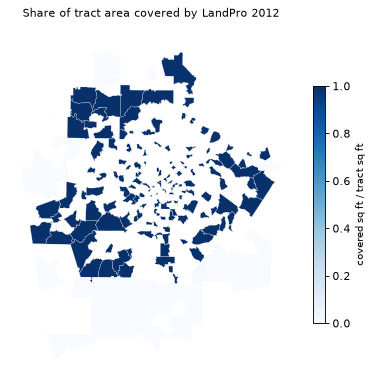

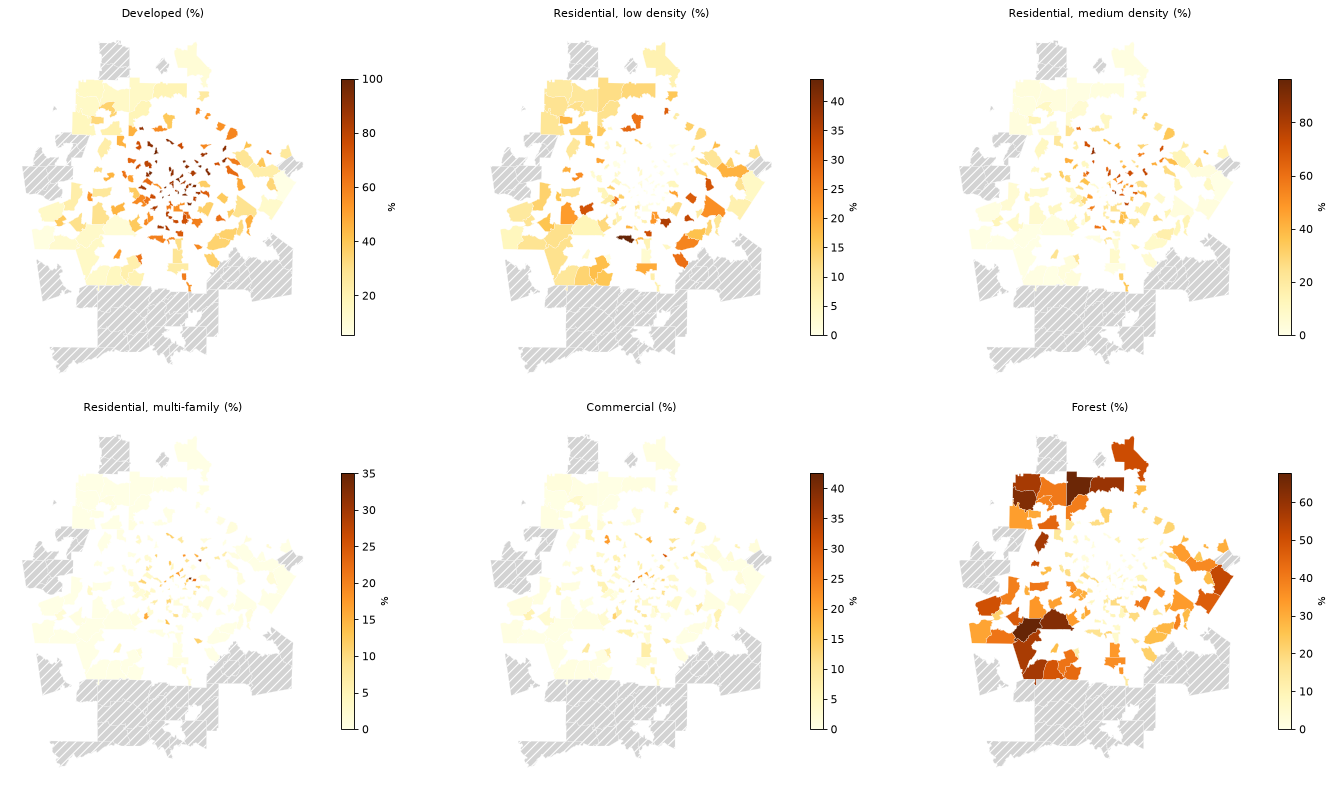

,all covered tracts,HIGH,LOW
mean share (%),,,
lu_pct_developed,56.63,74.27,47.05
lu_pct_undeveloped,33.72,16.45,43.10
lu_pct_undevelopable,9.65,9.28,9.85
lu_pct_agriculture,9.36,2.05,13.33
lu_pct_airport,0.17,0.06,0.24
lu_pct_cemeteries,0.21,0.38,0.11
lu_pct_church,0.78,1.19,0.56
lu_pct_commercial,4.69,6.18,3.89
lu_pct_cst,0.95,1.32,0.75


In [22]:
cov = tract_gdf["landpro_coverage_frac"]
band = pd.Categorical(np.select([cov >= 0.99, cov >= 0.5, cov > 0], [">= 0.99 (shares kept)", "0.5 to 0.99", "0 to 0.5"], "0 (outside ARC region)"),
                      categories=[">= 0.99 (shares kept)", "0.5 to 0.99", "0 to 0.5", "0 (outside ARC region)"], ordered=True)
display(pd.crosstab(band, tract_gdf["cluster"], margins=True, rownames=["LandPro coverage"]))
covered_tracts = cov >= 0.99
print(f"tracts with LandPro coverage >= 0.99: {covered_tracts.sum()} of {len(tract_gdf)}")

# Overlap check: the pieces of a tract sum to more than its area only if LandPro polygons overlap.
print(f"max coverage: {cov.max():.6f}; tracts with coverage > 1.0001 (overlapping LandPro polygons): {(cov > 1.0001).sum()}")
assert cov.max() <= 1.001
assert np.allclose(tract_gdf.loc[covered_tracts, LU_CLASS_COLS].sum(axis=1), 100, atol=0.5)
assert np.allclose(tract_gdf.loc[covered_tracts, LU_DE3_COLS].sum(axis=1), 100, atol=0.5)

sanity_report(tract_gdf, ["landpro_coverage_frac"] + LU_DE3_COLS)
plot_choropleth(tract_gdf, "landpro_coverage_frac", "Share of tract area covered by LandPro 2012", cmap="Blues", legend_label="covered sq ft / tract sq ft")
plt.show()

LU_MAP = {"lu_pct_developed": "Developed (%)", "lu_pct_res_low": "Residential, low density (%)", "lu_pct_res_med": "Residential, medium density (%)",
          "lu_pct_res_multi": "Residential, multi-family (%)", "lu_pct_commercial": "Commercial (%)", "lu_pct_forest": "Forest (%)"}
plot_choropleths(tract_gdf, list(LU_MAP), list(LU_MAP.values()), ncols=3, legend_labels=["%"] * len(LU_MAP), cmap="YlOrBr")

with pd.option_context("display.max_rows", 40):
    display(pd.DataFrame({"all covered tracts": tract_gdf[LU_COLS].mean(), **tract_gdf.groupby("cluster")[LU_COLS].mean().T})
            .round(2).rename_axis("mean share (%)"))

### 9.1 Land-use coverage gaps (data request)

- LandPro 2012 covers only the Atlanta Regional Commission (ARC) region, so it does not reach every
  study tract.
- The tracts with less than 99% coverage have blank (NaN) land-use shares (`lu_pct_*`). Some are partly
  covered and some have no coverage at all; the crosstab below counts them by cluster.
- The map shows the coverage status of every study tract and labels the gap tracts. The table below, saved
  as `data/processed/tract_landuse_coverage_gaps.csv`, lists the tracts for which land-use data needs to be
  sourced to fill the gap, sorted by coverage. `missing_area_sqmi` is the tract area outside LandPro.
  A few "Partial" tracts touch the ARC region only along their edge, so their coverage rounds to 0.0%.
- The lon/lat bounding box (EPSG:4326) of the gap tracts is printed at the end, as an extent for
  downloading replacement data.
- **Filled by NLCD.** Section 11.1 adds NLCD 2011 land cover (`nlcd11_*`) for all study tracts. It is a
  different, coarser class scheme (land cover, not land use), so it sits beside `lu_pct_*` rather than
  filling those columns.

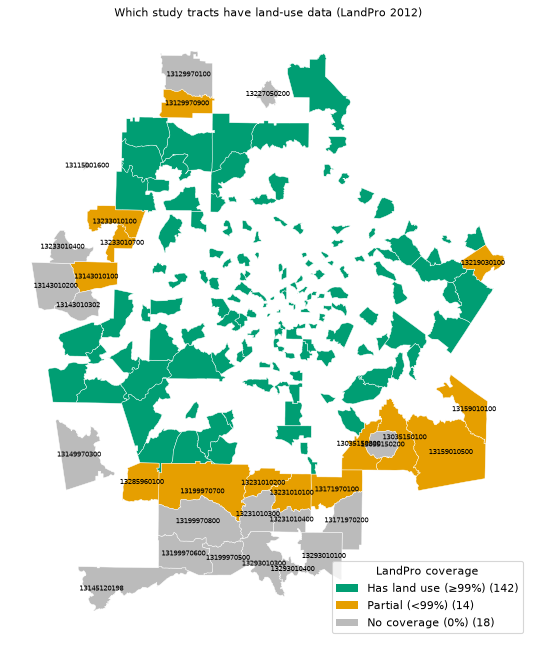

cluster,HIGH,LOW,All
landuse_status,,,
Has land use (≥99%),50,92,142
Partial (<99%),0,14,14
No coverage (0%),0,18,18
All,50,124,174


,TractGeoID,cluster,landpro_coverage_pct,missing_area_sqmi,landuse_status
0,13035150200,LOW,0.0,38.3,No coverage (0%)
1,13115001600,LOW,0.0,1.7,No coverage (0%)
2,13129970100,LOW,0.0,98.1,No coverage (0%)
3,13143010200,LOW,0.0,93.6,No coverage (0%)
4,13143010302,LOW,0.0,43.3,No coverage (0%)
5,13145120198,LOW,0.0,127.4,No coverage (0%)
6,13149970300,LOW,0.0,116.8,No coverage (0%)
7,13171970200,LOW,0.0,78.8,No coverage (0%)
8,13199970500,LOW,0.0,58.3,No coverage (0%)
9,13199970600,LOW,0.0,89.2,No coverage (0%)


Gap tracts bounding box (EPSG:4326; min lon, min lat, max lon, max lat): -85.387, 32.720, -83.460, 34.624
gap tracts: 32 (14 partial, 18 with no coverage); tracts with land use: 142


In [23]:
STATUS_COLORS = {"Has land use (≥99%)": "#009E73", "Partial (<99%)": "#E69F00", "No coverage (0%)": "#BBBBBB"}
landuse_status = pd.Series(pd.Categorical(np.select([cov >= 0.99, cov > 0], list(STATUS_COLORS)[:2], "No coverage (0%)"),
                                          categories=list(STATUS_COLORS)), index=tract_gdf.index, name="landuse_status")
gap = cov < 0.99

fig, ax = plt.subplots(figsize=(10, 10))
tract_gdf.plot(ax=ax, color=landuse_status.map(STATUS_COLORS).astype(str), edgecolor="white", linewidth=0.4)
for tract_id, pt in zip(tract_gdf.loc[gap, "TractGeoID"], tract_gdf.loc[gap].representative_point()):
    ax.annotate(tract_id, (pt.x, pt.y), ha="center", va="center", fontsize=6)
ax.legend(handles=[Patch(facecolor=c, label=f"{s} ({(landuse_status == s).sum()})") for s, c in STATUS_COLORS.items()],
          loc="lower right", title="LandPro coverage")
ax.set_title("Which study tracts have land-use data (LandPro 2012)")
ax.set_axis_off()
plt.show()

display(pd.crosstab(landuse_status, tract_gdf["cluster"], margins=True))

gaps = pd.DataFrame({
    "TractGeoID": tract_gdf["TractGeoID"], "cluster": tract_gdf["cluster"],
    "landpro_coverage_pct": (cov * 100).round(1),
    "missing_area_sqmi": (tract_gdf["tract_area_sqft"] * (1 - cov) / 27_878_400).round(1),
    "landuse_status": landuse_status,
})[gap].loc[cov[gap].sort_values(kind="stable").index].reset_index(drop=True)
with pd.option_context("display.max_rows", 60):
    display(gaps)
gaps.to_csv(PROCESSED / "tract_landuse_coverage_gaps.csv", index=False)

bbox = tract_gdf.loc[gap].to_crs(4326).total_bounds.round(3)
print(f"Gap tracts bounding box (EPSG:4326; min lon, min lat, max lon, max lat): {', '.join(f'{v:.3f}' for v in bbox)}")
n_none = (cov == 0).sum()
print(f"gap tracts: {len(gaps)} ({len(gaps) - n_none} partial, {n_none} with no coverage); tracts with land use: {covered_tracts.sum()}")
assert len(gaps) == gap.sum() == len(tract_gdf) - covered_tracts.sum()
assert (gaps["landuse_status"] == "No coverage (0%)").sum() == n_none

## 10. Air quality (EPA EQUATES CMAQ v5.3.2, 12 km grid, July 2010)

**Data.** `Daily_EQUATES_CMAQv532_cb6r3_ae7_aq_STAGE_12US1_201007.csv`: EPA EQUATES CMAQ v5.3.2 model
output, public. It holds daily values for every cell of the continental-US 12 km grid (12US1) from
2010-07-01 to 2010-07-31: 816 MB, about 4.25 million rows. Each row gives the cell's `column`/`row`,
its **centre** in lon/lat and in the grid's Lambert Conformal Conic metres (`Lambert_X`,
`LAMBERT_Y`), and 14 pollutant fields:
- **gases, in ppb:** `O3_MDA8` (maximum daily 8-hour average ozone), `O3_AVG`, `CO_AVG`, `NO_AVG`,
  `NO2_AVG`, `SO2_AVG`, `CH2O_AVG` (formaldehyde);
- **particles, in µg/m³:** `PM10_AVG`, `PM25_AVG` and the PM2.5 components `PM25_SO4_AVG`,
  `PM25_NO3_AVG`, `PM25_NH4_AVG`, `PM25_OC_AVG` (organic carbon), `PM25_EC_AVG` (elemental carbon).

Some values are written in Fortran E notation (e.g. `0.400925E-02`), which pandas parses as numbers.

**Method.**
1. **Read in chunks.** The CSV is read 500,000 rows at a time, and only the rows inside the study
   tracts' lon/lat bounding box plus 0.5° are kept. This keeps memory use small.
2. **July mean.** Each pollutant is averaged over the 31 days for each cell.
3. **Grid cells as squares.** Each cell is rebuilt as a 12 km square around its centre, in the CMAQ
   Lambert Conformal Conic projection (spherical earth, standard parallels 33° and 45°, origin
   40° N 97° W). The projection is **validated** first: the cell centres, reprojected to lon/lat, must
   match the file's `longitude`/`latitude` to within 0.01°. The squares are then reprojected to
   EPSG:2240.
4. **Area-weighted mean.** Tracts and cells are intersected (`gpd.overlay`), and each tract gets the
   area-weighted mean of the cells it overlaps, as for walkability (Section 6).

**Why area weighting rather than the nearest grid point.** Most tracts are much smaller than a 12 km cell,
but some straddle two or more cells. The nearest point to a tract's centre takes one cell's value and ignores
the rest of the tract. Area weighting uses every cell in proportion to how much of the tract it covers, and
it is the method of the ZIP table. The earlier ArcGIS tract-level methodology used the nearest grid point,
so these tract values are not computed the same way as that earlier work.

Columns are named `aq_<field>_jul2010` (e.g. `aq_pm25_avg_jul2010`); units are in the data dictionary.

**Caveats.**
- **One month.** July values describe summer conditions. Ozone in particular is strongly seasonal, so
  these are not annual exposures.
- **Vintage.** 2010, against 2011–2012 for most other layers.
- **Model output, not monitor readings.**
- **12 km resolution.** Neighbouring tracts often share the same cells, and so have identical values.
  Contrasts within the urban core are smoothed out.

**Sanity check.**
- Every tract must be fully covered by grid cells (coverage ≥ 0.999).
- Every value must be ≥ 0.

In [24]:
AQ_CSV = RAW_TABLES / "Daily_EQUATES_CMAQv532_cb6r3_ae7_aq_STAGE_12US1_201007.csv"
AQ_FIELDS = {  # field: (description, unit)
    "O3_MDA8": ("Ozone, maximum daily 8-hour average", "ppb"), "O3_AVG": ("Ozone, daily average", "ppb"),
    "CO_AVG": ("Carbon monoxide", "ppb"), "NO_AVG": ("Nitric oxide", "ppb"), "NO2_AVG": ("Nitrogen dioxide", "ppb"),
    "SO2_AVG": ("Sulfur dioxide", "ppb"), "CH2O_AVG": ("Formaldehyde", "ppb"),
    "PM10_AVG": ("PM10", "ug/m3"), "PM25_AVG": ("PM2.5", "ug/m3"), "PM25_SO4_AVG": ("PM2.5 sulfate", "ug/m3"),
    "PM25_NO3_AVG": ("PM2.5 nitrate", "ug/m3"), "PM25_NH4_AVG": ("PM2.5 ammonium", "ug/m3"),
    "PM25_OC_AVG": ("PM2.5 organic carbon", "ug/m3"), "PM25_EC_AVG": ("PM2.5 elemental carbon", "ug/m3"),
}
AQ_COLS = [f"aq_{f.lower()}_jul2010" for f in AQ_FIELDS]

lon_min, lat_min, lon_max, lat_max = tract_gdf.to_crs("EPSG:4326").total_bounds + np.array([-0.5, -0.5, 0.5, 0.5])
parts, n_rows = [], 0
for chunk in pd.read_csv(AQ_CSV, chunksize=500_000,
                         usecols=["column", "row", "longitude", "latitude", "Lambert_X", "LAMBERT_Y", "date", *AQ_FIELDS]):
    n_rows += len(chunk)
    parts.append(chunk[chunk["longitude"].between(lon_min, lon_max) & chunk["latitude"].between(lat_min, lat_max)])
aq_daily = pd.concat(parts, ignore_index=True)
print(f"rows read: {n_rows:,}; kept in the buffered study bbox: {len(aq_daily):,}; "
      f"dates: {aq_daily['date'].min()} to {aq_daily['date'].max()} ({aq_daily['date'].nunique()})")

cell = aq_daily.groupby(["column", "row"])
assert (cell["date"].nunique() == 31).all() and (cell.size() == 31).all()
aq_cells = cell.agg({"Lambert_X": "first", "LAMBERT_Y": "first", "longitude": "first", "latitude": "first", **{f: "mean" for f in AQ_FIELDS}}).reset_index()
print(f"grid cells in the buffered bbox: {len(aq_cells)}")

# Grid geometry: centres 12,000 m apart; the 12US1 grid origin (XORIG) is -2,556,000 m, so column 1 is centred at -2,550,000 m.
assert ((aq_cells["Lambert_X"] + 2_556_000) / 12_000 + 0.5 == aq_cells["column"]).all()

CMAQ_LCC = "+proj=lcc +lat_1=33 +lat_2=45 +lat_0=40 +lon_0=-97 +x_0=0 +y_0=0 +a=6370000 +b=6370000 +units=m +no_defs"
centres = gpd.GeoSeries(gpd.points_from_xy(aq_cells["Lambert_X"], aq_cells["LAMBERT_Y"]), crs=CMAQ_LCC).to_crs("EPSG:4326")
crs_error = np.maximum((centres.x - aq_cells["longitude"]).abs(), (centres.y - aq_cells["latitude"]).abs())
print(f"CRS validation: max |reprojected centre - file lon/lat| = {crs_error.max():.2e} degrees")
assert crs_error.max() < 0.01, "CMAQ LCC definition does not reproduce the file's lon/lat"

aq_cells_gdf = gpd.GeoDataFrame(aq_cells, geometry=[box(x - 6000, y - 6000, x + 6000, y + 6000) for x, y in zip(aq_cells["Lambert_X"], aq_cells["LAMBERT_Y"])],
                                crs=CMAQ_LCC).to_crs(TARGET_CRS)

rows read: 4,254,471; kept in the buffered study bbox: 18,755; dates: 2010-07-01 to 2010-07-31 (31)
grid cells in the buffered bbox: 605
CRS validation: max |reprojected centre - file lon/lat| = 8.53e-06 degrees


aq_o3_mda8_jul2010         174
aq_o3_avg_jul2010          174
aq_co_avg_jul2010          174
aq_no_avg_jul2010          174
aq_no2_avg_jul2010         174
aq_so2_avg_jul2010         174
aq_ch2o_avg_jul2010        174
aq_pm10_avg_jul2010        174
aq_pm25_avg_jul2010        174
aq_pm25_so4_avg_jul2010    174
aq_pm25_no3_avg_jul2010    174
aq_pm25_nh4_avg_jul2010    174
aq_pm25_oc_avg_jul2010     174
aq_pm25_ec_avg_jul2010     174
grid-cell coverage of tract area: min 1.000000, max 1.000000; distinct cells touching the study tracts: 203; cells per tract: 1 to 10


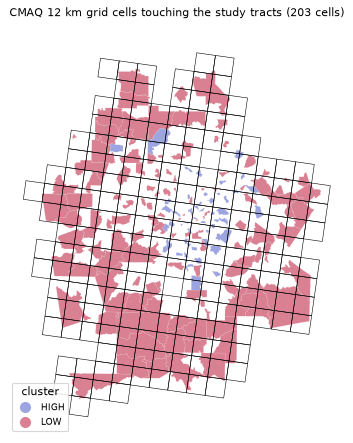

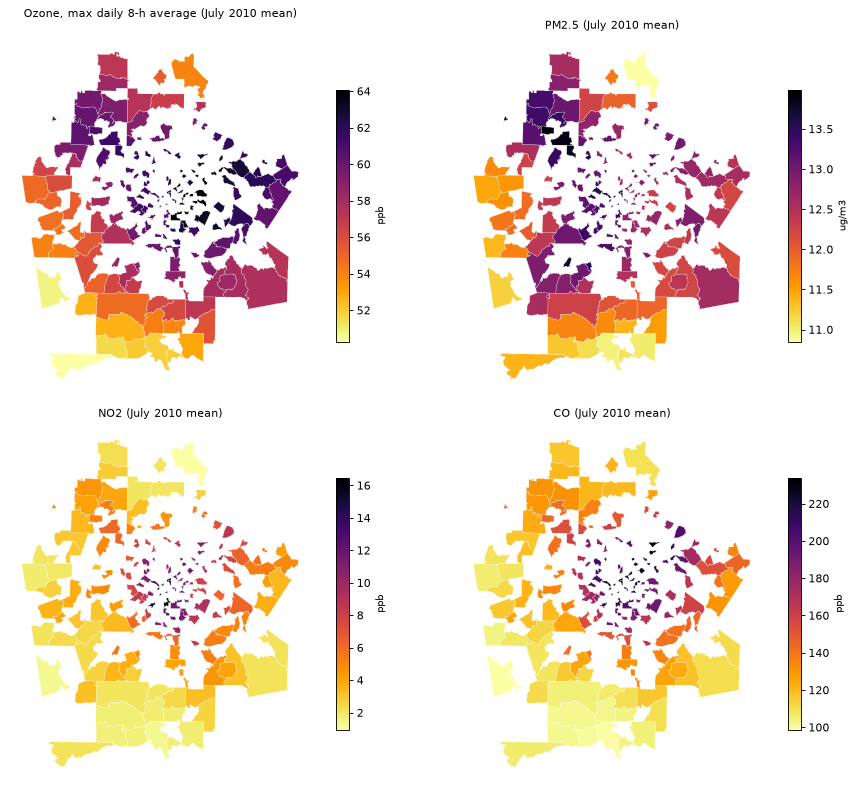

,n,n_null,pct_null,min,p25,median,p75,max,n_zero,n_negative
aq_o3_mda8_jul2010,174,0,0.0,50.262195,57.716159,60.545792,61.956660,64.089445,0,0
aq_o3_avg_jul2010,174,0,0.0,34.547552,37.326907,38.447072,40.150534,42.952426,0,0
aq_co_avg_jul2010,174,0,0.0,98.550201,123.887518,154.199250,197.016657,233.963419,0,0
aq_no_avg_jul2010,174,0,0.0,0.052165,0.282744,0.654324,1.415108,4.280558,0,0
aq_no2_avg_jul2010,174,0,0.0,0.929659,3.454684,5.823966,9.291985,16.477144,0,0
aq_so2_avg_jul2010,174,0,0.0,0.483932,0.817140,1.026155,1.317586,3.024902,0,0
aq_ch2o_avg_jul2010,174,0,0.0,2.895847,3.374980,3.450463,3.552658,3.832776,0,0
aq_pm10_avg_jul2010,174,0,0.0,16.211791,18.447240,18.995905,19.501201,21.092689,0,0
aq_pm25_avg_jul2010,174,0,0.0,10.847028,12.298109,12.722206,13.067667,13.990770,0,0
aq_pm25_so4_avg_jul2010,174,0,0.0,1.837313,2.155490,2.224199,2.293416,2.624245,0,0


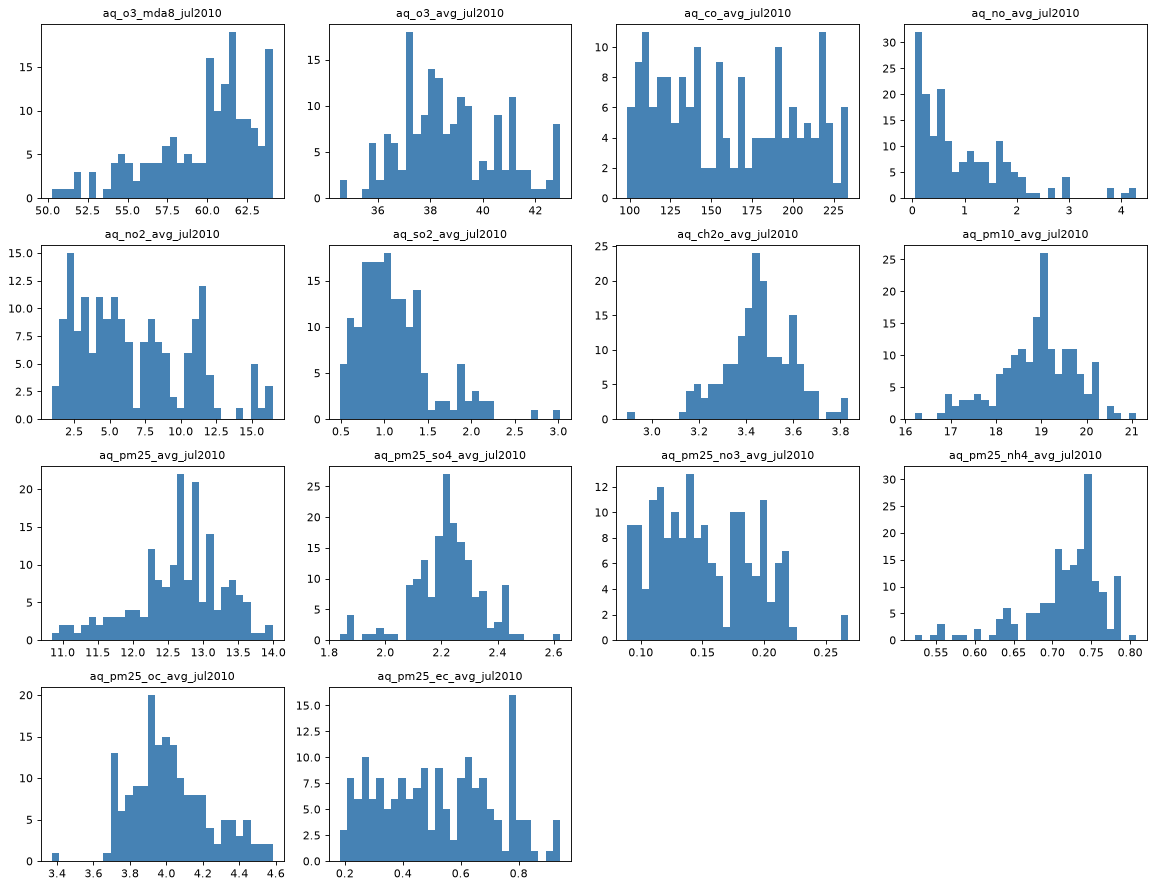

In [25]:
pieces = gpd.overlay(tract_gdf[["TractGeoID", "geometry"]], aq_cells_gdf[["column", "row", *AQ_FIELDS, "geometry"]], how="intersection", keep_geom_type=True)
pieces["w"] = pieces.area
sums = pieces.groupby("TractGeoID")
aq_tract = pieces[list(AQ_FIELDS)].mul(pieces["w"], axis=0).groupby(pieces["TractGeoID"]).sum().div(sums["w"].sum(), axis=0)
tract_gdf = join_tract(tract_gdf, aq_tract.set_axis(AQ_COLS, axis=1))

coverage = sums["w"].sum() / tract_gdf.set_index("TractGeoID")["tract_area_sqft"]
touched = pieces[["column", "row"]].drop_duplicates()
print(f"grid-cell coverage of tract area: min {coverage.min():.6f}, max {coverage.max():.6f}; "
      f"distinct cells touching the study tracts: {len(touched)}; cells per tract: {sums.size().min()} to {sums.size().max()}")
assert len(coverage) == len(tract_gdf) and (coverage >= 0.999).all()
assert (tract_gdf[AQ_COLS] >= 0).all().all()

ax = tract_gdf.plot(column="cluster", cmap="coolwarm", alpha=0.5, edgecolor="white", linewidth=0.2, figsize=(7, 6.5), legend=True,
                    legend_kwds={"title": "cluster", "loc": "lower left", "fontsize": 8})
aq_cells_gdf.merge(touched).boundary.plot(ax=ax, color="black", linewidth=0.5)
ax.set_title(f"CMAQ 12 km grid cells touching the study tracts ({len(touched)} cells)")
ax.set_axis_off()
plt.show()

AQ_MAP = {"aq_o3_mda8_jul2010": ("Ozone, max daily 8-h average (July 2010 mean)", "ppb"), "aq_pm25_avg_jul2010": ("PM2.5 (July 2010 mean)", "ug/m3"),
          "aq_no2_avg_jul2010": ("NO2 (July 2010 mean)", "ppb"), "aq_co_avg_jul2010": ("CO (July 2010 mean)", "ppb")}
plot_choropleths(tract_gdf, list(AQ_MAP), [t for t, _ in AQ_MAP.values()], legend_labels=[u for _, u in AQ_MAP.values()], cmap="inferno_r")
sanity_report(tract_gdf, AQ_COLS)

## 11. Remote-sensing rasters (NDVI, impervious surface, LST, LAI)

**Data.** Four single-band GeoTIFFs in `data/raw/rasters/`, all in EPSG:4326. They cover the whole of
Georgia (−85.61 to −80.84 lon, 30.36 to 35.02 lat), so they cover every study tract.

| File | Variable | Pixel | Values in the study area | No data |
|---|---|---|---|---|
| `ga_ndvi_2011_2012-002.tif` | NDVI, 2011–2012 composite (Landsat 4-5 TM) | ~30 m | −0.50 to 0.90 | NaN |
| `ga_impervious_2011.tif` | Fractional impervious surface, 2011 (Annual NLCD) | ~30 m | 0 to 100 % | none |
| `ga_lst_2011_2012-001.tif` | Land surface temperature, 2011–2012 composite (Landsat 4-5 TM, Level-2 ST) | ~30 m | 7 to 66 °C | NaN |
| `ga_lai_2011_2012.tif` | Leaf area index, 2011–2012 composite | ~500 m | 0.3 to 5.3, plus 25.5 | NaN and 25.5 |

**Method.** A **zonal mean**, as ArcGIS *Zonal Statistics as Table* with statistic MEAN (methodology
§8c, where the zones were tracts):
1. The tracts are reprojected to the raster CRS (EPSG:4326). The rasters are **not** resampled or
   reprojected, so every pixel keeps its delivered value.
2. Only the window covering the study tracts is read.
3. The tracts are rasterized onto the raster grid. A pixel belongs to a tract if its **centre** lies inside
   the tract (the ArcGIS default), so each pixel counts for at most one tract.
4. Tract value = mean of its valid pixels. No-data pixels are ignored.

**Why a plain pixel mean.** In EPSG:4326 a pixel's ground area shrinks with latitude, but only by about
2% between the southern and northern edges of the study area (cos 32.8° vs cos 34.6°), and by much less
within one tract. The unweighted pixel mean is therefore effectively an area-weighted mean.

**LAI.**
- **25.5 is a fill value.** LAI products store LAI × 10 as an integer and use 249–255 as fill codes;
  255 × 0.1 = 25.5. These pixels are set to no data. The next-highest value is 5.3.
- **LAI is missing over built-up land.** No LAI is retrieved for non-vegetated land-cover classes such as
  urban and water, so a tract's share of valid LAI pixels falls sharply as its impervious cover rises.
  `rs_lai_mean` is therefore the mean over the **vegetated** part of the tract only, and it is NaN for tracts
  with no valid pixel, which are in the urban core. `rs_lai_valid_frac` (valid pixels / all pixels)
  is kept so that LAI values can be filtered.
- At ~500 m, a small tract holds only a few LAI pixels.

**Caveats.**
- The compositing period (season, statistic) of the NDVI, LST and LAI composites is still to be
  confirmed. LST is assumed to be in °C. Its range (study-area median about 30 °C) is consistent with a
  warm-season, daytime Landsat surface temperature.
- Water inside a tract is included: it lowers NDVI (negative over water) and the impervious share (0).
- The 2011–2012 vintage matches the c. 2011 energy data.
- Small tracts hold few pixels, so their means are noisier than the ZIP means.

**Sanity check.**
- NDVI and impervious: every tract has at least 95% valid pixels. LST has small no-data gaps: every tract
  has at least 90%, and the few below 95% are printed (the ZIP table's threshold of 95% is met by all ZIPs).
- Every tract mean lies in its physical range: NDVI in [−1, 1], impervious in [0, 100] %, LAI in [0, 10].
- Cross-check against the vector layers: the impervious share must track the Microsoft building coverage
  (Spearman ρ > 0.8), and NDVI must fall as the impervious share rises (ρ < −0.8).

,file,crs,width x height,dtype,pixel (deg),nodata tag,bounds
0,ga_ndvi_2011_2012-002.tif,EPSG:4326,17701 x 17305,float64,0.000269,None,"(-85.61, 30.36, -80.84, 35.02)"
1,ga_impervious_2011.tif,EPSG:4326,17701 x 17305,uint8,0.000269,None,"(-85.61, 30.36, -80.84, 35.02)"
2,ga_lst_2011_2012-001.tif,EPSG:4326,17701 x 17305,float64,0.000269,None,"(-85.61, 30.36, -80.84, 35.02)"
3,ga_lai_2011_2012.tif,EPSG:4326,1063 x 1039,float64,0.004492,None,"(-85.61, 30.36, -80.84, 35.03)"


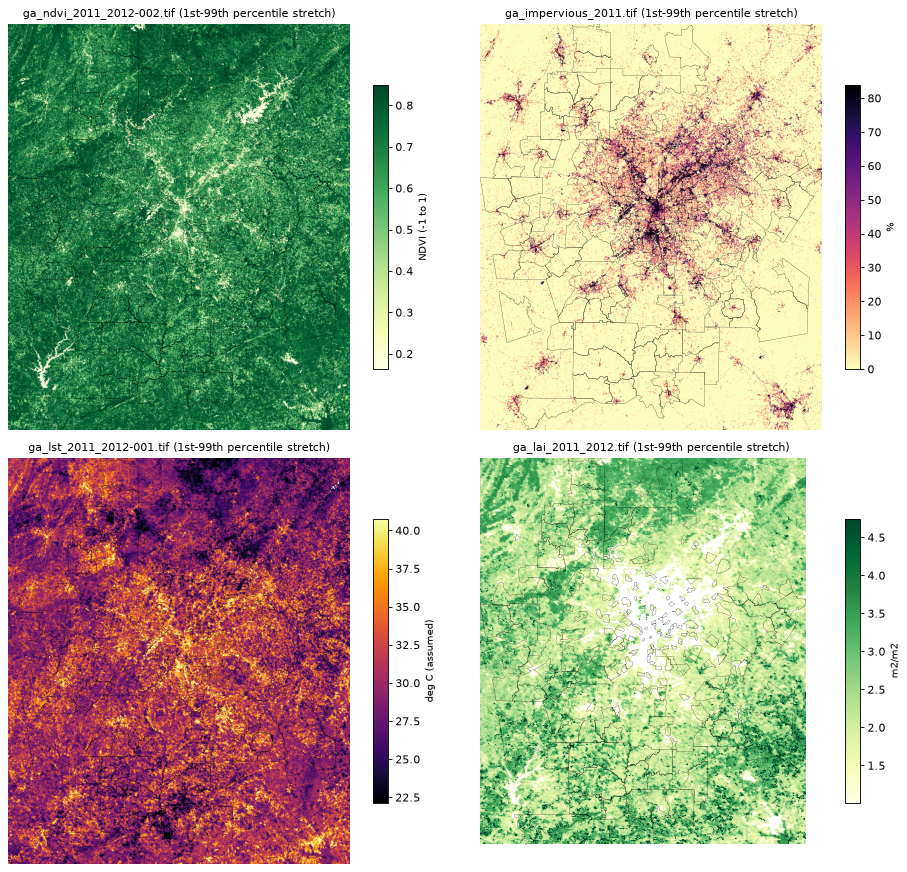

In [26]:
RASTERS = {  # column: (file, description, unit, source, fill values other than NaN)
    "rs_ndvi_mean": ("ga_ndvi_2011_2012-002.tif", "NDVI, 2011-2012 composite, tract mean", "NDVI (-1 to 1)",
                     "Landsat 4-5 TM NDVI composite 2011-2012", ()),
    "rs_impervious_pct_mean": ("ga_impervious_2011.tif", "Fractional impervious surface 2011, tract mean", "%",
                               "MRLC Annual NLCD fractional impervious surface 2011", ()),
    "rs_lst_c_mean": ("ga_lst_2011_2012-001.tif", "Land surface temperature, 2011-2012 composite, tract mean", "deg C (assumed)",
                      "Landsat 4-5 TM Level-2 surface temperature composite 2011-2012", ()),
    "rs_lai_mean": ("ga_lai_2011_2012.tif", "Leaf area index, 2011-2012 composite, mean over valid (vegetated) pixels", "m2/m2",
                    "500 m LAI composite 2011-2012", (25.5,)),
}
RS_CMAPS = {"rs_ndvi_mean": "YlGn", "rs_impervious_pct_mean": "magma_r", "rs_lst_c_mean": "inferno", "rs_lai_mean": "YlGn"}
RS_COLS = list(RASTERS) + ["rs_lai_valid_frac"]


def read_zones(path, zones):
    """Raster window over `zones` (1-pixel margin) and its zone labels: 1-based zone index of the polygon holding each pixel centre, 0 = none."""
    with rasterio.open(path) as src:
        z = zones.to_crs(src.crs)
        minx, miny, maxx, maxy = z.total_bounds
        rx, ry = src.res
        win = from_bounds(minx - rx, miny - ry, maxx + rx, maxy + ry, src.transform).round_offsets().round_lengths()
        data = src.read(1, window=win)
        transform = src.window_transform(win)
    labels = rasterize(zip(z.geometry, range(1, len(z) + 1)), out_shape=data.shape, transform=transform, fill=0, dtype="int32")
    return data, labels


def zonal_mean(path, zones, fill_values=()):
    """Mean of the valid pixels whose centre lies in each zone (as ArcGIS Zonal Statistics, MEAN), on the raster's own grid."""
    data, labels = read_zones(path, zones)
    data = data.astype("float64")
    data[np.isin(data, fill_values)] = np.nan
    valid = np.isfinite(data) & (labels > 0)
    n = len(zones) + 1
    n_pixels = np.bincount(labels.ravel(), minlength=n)[1:]
    n_valid = np.bincount(labels[valid], minlength=n)[1:]
    total = np.bincount(labels[valid], weights=data[valid], minlength=n)[1:]
    with np.errstate(invalid="ignore"):
        return pd.DataFrame({"mean": total / n_valid, "n_pixels": n_pixels, "valid_frac": n_valid / n_pixels}, index=zones["TractGeoID"].to_numpy())


inventory = []
for f, *_ in RASTERS.values():
    with rasterio.open(RAW_RASTERS / f) as src:
        inventory.append({"file": f, "crs": src.crs.to_string(), "width x height": f"{src.width} x {src.height}", "dtype": src.dtypes[0],
                          "pixel (deg)": round(src.res[0], 6), "nodata tag": src.nodata, "bounds": tuple(round(b, 2) for b in src.bounds)})
display(pd.DataFrame(inventory))

# Preview: each raster over the study area (decimated to about 800 px wide), with the tract outlines
tracts_ll = tract_gdf.to_crs("EPSG:4326")
fig, axes = plt.subplots(2, 2, figsize=(12, 11))
for ax, (col, (f, desc, unit, _, fills)) in zip(axes.flat, RASTERS.items()):
    with rasterio.open(RAW_RASTERS / f) as src:
        win = from_bounds(*tracts_ll.total_bounds, src.transform).round_offsets().round_lengths()
        step = max(1, round(win.width / 800))
        img = src.read(1, window=win, out_shape=(win.height // step, win.width // step), resampling=Resampling.nearest).astype("float64")
        left, bottom, right, top = rasterio.windows.bounds(win, src.transform)
    img[np.isin(img, fills)] = np.nan
    im = ax.imshow(img, extent=(left, right, bottom, top), cmap=RS_CMAPS[col], vmin=np.nanpercentile(img, 1), vmax=np.nanpercentile(img, 99))
    tracts_ll.boundary.plot(ax=ax, color="black", linewidth=0.2)
    fig.colorbar(im, ax=ax, shrink=0.7, label=unit)
    ax.set_title(f"{f} (1st-99th percentile stretch)")
    ax.set_axis_off()
fig.tight_layout()
plt.show()

,"pixels per tract, min","pixels per tract, median","valid share, min",tracts with valid share < 0.99,tracts with a value
rs_ndvi_mean,1398.0,34246.0,1.000000,0.0,174.0
rs_impervious_pct_mean,1398.0,34246.0,1.000000,0.0,174.0
rs_lst_c_mean,1398.0,34246.0,0.915723,1.0,174.0
rs_lai_mean,4.0,126.0,0.000000,106.0,153.0


rs_ndvi_mean              174
rs_impervious_pct_mean    174
rs_lst_c_mean             174
rs_lai_mean               153
rs_lai_valid_frac         174
tracts with an LST valid share < 0.95: {'13067031001': 0.916}
Spearman: impervious vs building coverage 0.96; NDVI vs impervious -0.91; LST vs impervious 0.67; LAI vs NDVI 0.95
tracts with no valid LAI pixel (rs_lai_mean NaN): 21 of 174


,n,n_null,pct_null,min,p25,median,p75,max,n_zero,n_negative
rs_ndvi_mean,174,0,0.0,0.298903,0.601548,0.645775,0.698169,0.767554,0,0
rs_impervious_pct_mean,174,0,0.0,0.590171,2.560016,10.601532,23.305677,71.739394,0,0
rs_lst_c_mean,174,0,0.0,25.892466,30.246134,31.322040,32.657054,37.117524,0,0
rs_lai_mean,153,21,12.1,1.326515,1.740887,2.088420,2.439891,3.129151,0,0
rs_lai_valid_frac,174,0,0.0,0.000000,0.490854,0.962176,0.997587,1.000000,21,0


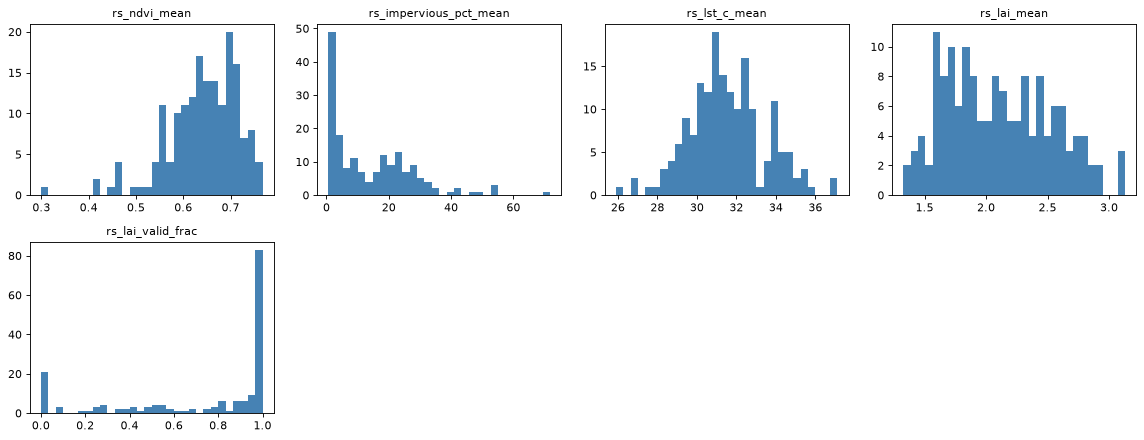

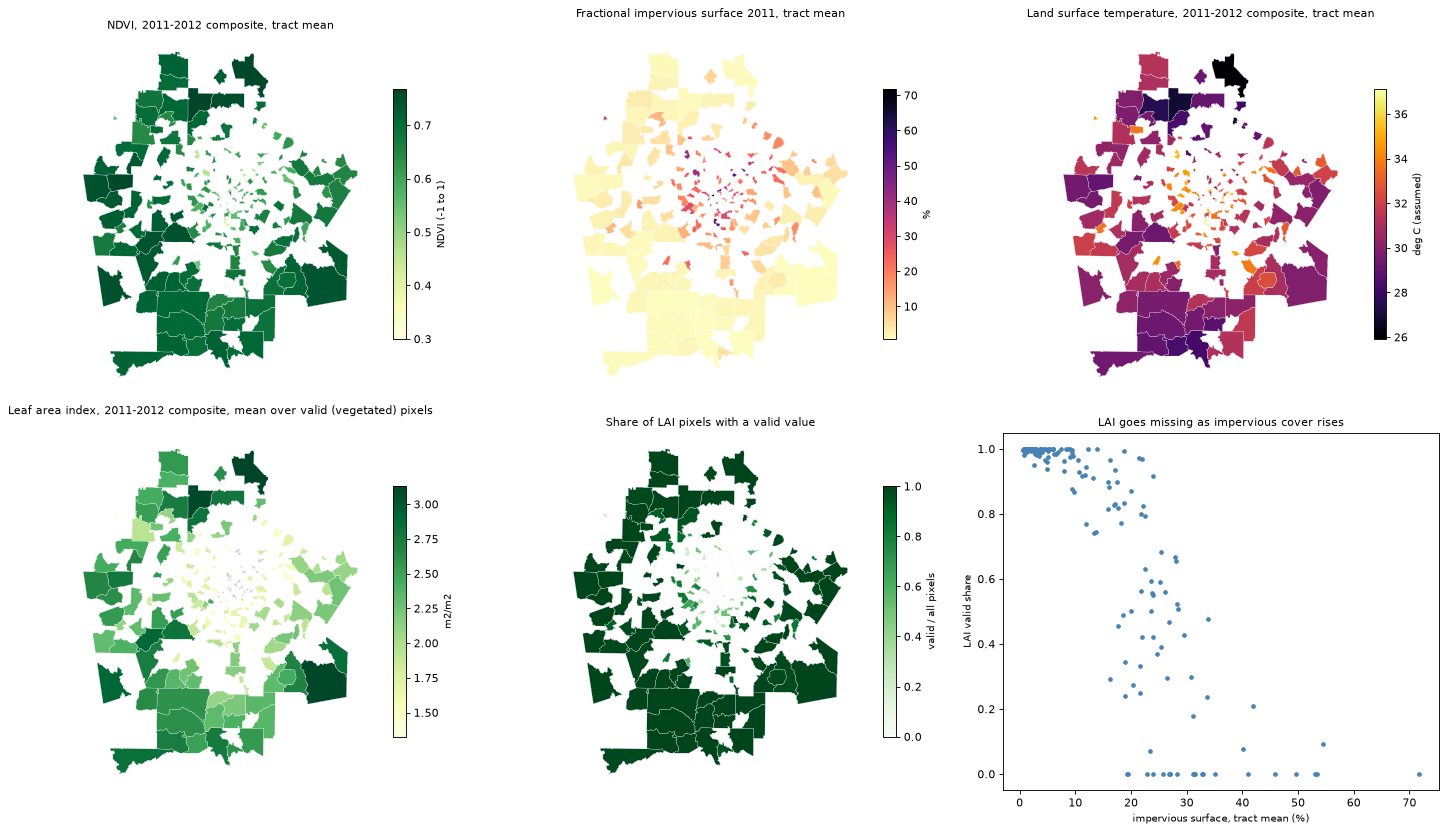

In [27]:
rs_stats = {col: zonal_mean(RAW_RASTERS / f, tract_gdf, fills) for col, (f, _, _, _, fills) in RASTERS.items()}
display(pd.DataFrame({col: {"pixels per tract, min": s["n_pixels"].min(), "pixels per tract, median": s["n_pixels"].median(),
                            "valid share, min": s["valid_frac"].min(), "tracts with valid share < 0.99": (s["valid_frac"] < 0.99).sum(),
                            "tracts with a value": s["mean"].notna().sum()} for col, s in rs_stats.items()}).T)
rs_tract = pd.DataFrame({col: s["mean"] for col, s in rs_stats.items()}).assign(rs_lai_valid_frac=rs_stats["rs_lai_mean"]["valid_frac"])
tract_gdf = join_tract(tract_gdf, rs_tract)

FULL_RS = ["rs_ndvi_mean", "rs_impervious_pct_mean", "rs_lst_c_mean"]
low_lst = rs_stats["rs_lst_c_mean"]["valid_frac"][lambda s: s < 0.95]
print(f"tracts with an LST valid share < 0.95: {low_lst.round(3).to_dict()}")
assert all(rs_stats[c]["valid_frac"].min() >= 0.95 for c in FULL_RS[:2]) and rs_stats["rs_lst_c_mean"]["valid_frac"].min() >= 0.90
assert tract_gdf[FULL_RS].notna().all().all()
assert tract_gdf["rs_ndvi_mean"].between(-1, 1).all() and tract_gdf["rs_impervious_pct_mean"].between(0, 100).all()
assert tract_gdf["rs_lai_mean"].dropna().between(0, 10).all() and tract_gdf["rs_lai_valid_frac"].between(0, 1).all()

rho = tract_gdf[FULL_RS + ["rs_lai_mean", "ms_bldg_coverage_ratio"]].corr(method="spearman")
print(f"Spearman: impervious vs building coverage {rho.loc['rs_impervious_pct_mean', 'ms_bldg_coverage_ratio']:.2f}; "
      f"NDVI vs impervious {rho.loc['rs_ndvi_mean', 'rs_impervious_pct_mean']:.2f}; "
      f"LST vs impervious {rho.loc['rs_lst_c_mean', 'rs_impervious_pct_mean']:.2f}; LAI vs NDVI {rho.loc['rs_lai_mean', 'rs_ndvi_mean']:.2f}")
assert rho.loc["rs_impervious_pct_mean", "ms_bldg_coverage_ratio"] > 0.8 and rho.loc["rs_ndvi_mean", "rs_impervious_pct_mean"] < -0.8
print(f"tracts with no valid LAI pixel (rs_lai_mean NaN): {tract_gdf['rs_lai_mean'].isna().sum()} of {len(tract_gdf)}")

sanity_report(tract_gdf, RS_COLS)
fig, axes = plt.subplots(2, 3, figsize=(18, 10.5))
for ax, col in zip(axes.flat, RASTERS):
    plot_choropleth(tract_gdf, col, RASTERS[col][1], ax=ax, cmap=RS_CMAPS[col], legend_label=RASTERS[col][2])
plot_choropleth(tract_gdf, "rs_lai_valid_frac", "Share of LAI pixels with a valid value", ax=axes[1, 1], cmap="Greens",
                legend_label="valid / all pixels")
axes[1, 2].scatter(tract_gdf["rs_impervious_pct_mean"], tract_gdf["rs_lai_valid_frac"], s=10, color="steelblue")
axes[1, 2].set(xlabel="impervious surface, tract mean (%)", ylabel="LAI valid share", title="LAI goes missing as impervious cover rises")
fig.tight_layout()
plt.show()

### 11.1 NLCD 2011 land cover

**Data.** `data/raw/rasters/nlcd_2011_land_cover/`: *National Land Cover Database (NLCD) 2011 Land Cover,
Conterminous United States*, 2011 edition released 2014-10-10 (USGS, [doi:10.5066/P97S2IID](https://doi.org/10.5066/P97S2IID)). A
30 m categorical raster (uint8) in Albers Conical Equal Area (NAD83), covering the whole conterminous US,
so it covers every study tract, unlike LandPro (Section 9.1). Its legend (CONUS, 2011):

| Group | Codes |
|---|---|
| Water | 11 open water (12 perennial ice/snow: absent in Georgia) |
| Developed | 21 open space, 22 low, 23 medium, 24 high intensity |
| Barren | 31 |
| Forest | 41 deciduous, 42 evergreen, 43 mixed |
| Shrub / herbaceous | 52 shrub/scrub, 71 grassland/herbaceous |
| Planted / cultivated | 81 pasture/hay, 82 cultivated crops |
| Wetlands | 90 woody, 95 emergent herbaceous |

**Method.** A **zonal class share**, the categorical counterpart of Section 11's zonal mean:
1. The tracts are reprojected to the raster CRS. The raster is **not** reprojected: resampling a categorical
   raster would invent or drop class pixels.
2. Only the window covering the study tracts is read, and pixels are assigned to a tract by their centre
   (`read_zones`, shared with `zonal_mean`).
3. Pixels per (tract, class) are counted. Each share is the class's pixels / the tract's classified pixels × 100.
   The CRS is **equal-area**, so pixel shares are area shares exactly.
4. Two group sums are added: `nlcd11_pct_developed` (21–24) and `nlcd11_pct_forest` (41–43).

Any value outside the legend (background / no data) is excluded from the denominator and counted in
`nlcd11_valid_frac`.

**Caveats.**
- **Land cover, not land use.** NLCD classifies what is on the ground from Landsat imagery. "Developed"
  classes are defined by impervious share, not by function (residential vs. commercial), so they do not
  map one-to-one onto LandPro's 29 land-use classes. The two sets are kept as separate columns.
- 30 m pixels: small features (narrow roads, single buildings) are mixed into neighbouring classes, and a
  small tract holds few pixels.
- 2011 matches the c. 2011 energy data.

**Sanity check.**
- Every tract has at least 99% classified pixels, and its class shares sum to 100%.
- Developed share must track the Annual NLCD impervious share of Section 11 (Spearman ρ > 0.8).
- On the LandPro-covered tracts, NLCD and LandPro developed shares are compared (reported, not asserted:
  the two define "developed" differently).

**Figures.** The maps and the LandPro comparison are also saved to `figures/nlcd_2011_landcover_maps_tract.png`
and `figures/nlcd_2011_vs_landpro_tract.png`.

,file,crs,width x height,dtype,pixel,nodata tag
0,nlcd_2011_landcover_2011_edition_2014_10_10.img,"PROJCS[""Albers Conical Equal Area"",GEOGCS[""NAD...",161190 x 104424,uint8,"(30.0, 30.0)",None


pixels in the study tracts by value: {11: 185409, 21: 1044981, 22: 511749, 23: 148901, 24: 71135, 31: 52784, 41: 4228934, 42: 2943776, 43: 304505, 52: 731092, 71: 868162, 81: 2157490, 82: 64939, 90: 450464, 95: 14749}
values outside the legend (treated as no data): []
nlcd11_pct_developed                       174
nlcd11_pct_forest                          174
nlcd11_pct_open_water                      174
nlcd11_pct_developed_open_space            174
nlcd11_pct_developed_low_intensity         174
nlcd11_pct_developed_medium_intensity      174
nlcd11_pct_developed_high_intensity        174
nlcd11_pct_barren_land                     174
nlcd11_pct_deciduous_forest                174
nlcd11_pct_evergreen_forest                174
nlcd11_pct_mixed_forest                    174
nlcd11_pct_shrub_scrub                     174
nlcd11_pct_grassland_herbaceous            174
nlcd11_pct_pasture_hay                     174
nlcd11_pct_cultivated_crops                174
nlcd11_pct_woody_wetlands 

,n,n_null,pct_null,min,p25,median,p75,max,n_zero,n_negative
nlcd11_pct_developed,174,0,0.0,3.449661,11.075811,38.501031,71.144831,100.000000,0,0
nlcd11_pct_forest,174,0,0.0,0.000000,22.727213,38.622817,52.178214,82.043540,2,0
nlcd11_pct_open_water,174,0,0.0,0.000000,0.306946,0.792316,1.355720,13.712849,21,0
nlcd11_pct_developed_open_space,174,0,0.0,2.647061,7.157966,18.937098,26.614731,48.238276,0,0
nlcd11_pct_developed_low_intensity,174,0,0.0,0.359517,2.768744,11.970260,23.930682,42.749462,0,0
nlcd11_pct_developed_medium_intensity,174,0,0.0,0.024826,0.527243,3.200043,9.222234,35.092025,0,0
nlcd11_pct_developed_high_intensity,174,0,0.0,0.001164,0.139979,0.949813,3.572689,41.411043,0,0
nlcd11_pct_barren_land,174,0,0.0,0.000000,0.081153,0.190868,0.488810,6.063237,35,0
nlcd11_pct_deciduous_forest,174,0,0.0,0.000000,9.948703,21.251381,28.056806,68.369176,2,0
nlcd11_pct_evergreen_forest,174,0,0.0,0.000000,10.125725,15.266113,20.709009,35.116705,3,0


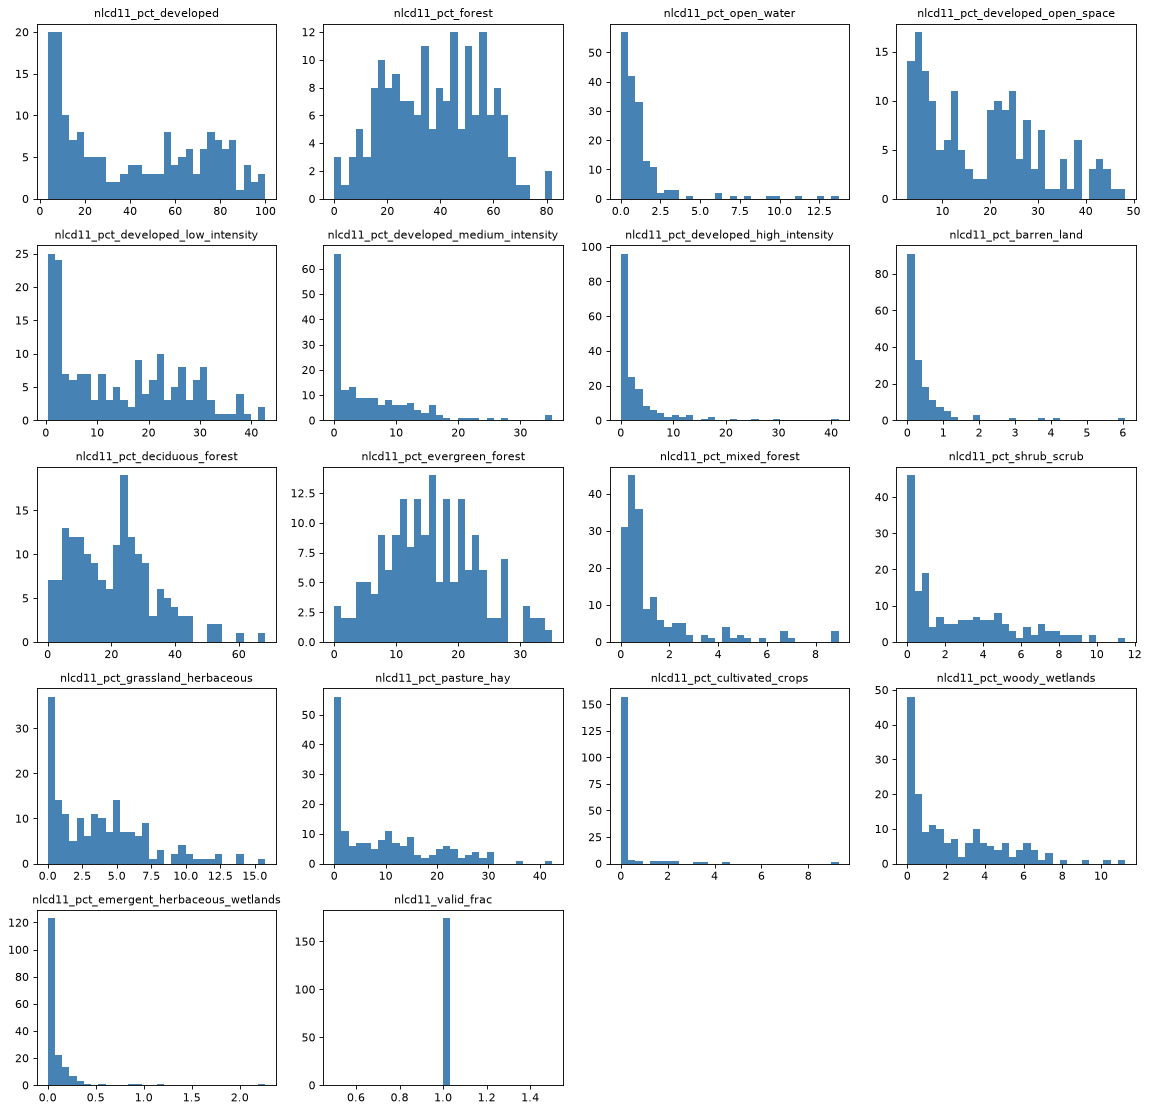

,all tracts,HIGH,LOW,former LandPro gap tracts
mean share (%),,,,
nlcd11_pct_developed,41.78,66.22,31.92,10.96
nlcd11_pct_forest,37.87,25.68,42.79,54.27
nlcd11_pct_open_water,1.33,1.24,1.37,1.13
nlcd11_pct_developed_open_space,18.62,27.84,14.90,6.46
nlcd11_pct_developed_low_intensity,14.44,23.70,10.70,3.31
nlcd11_pct_developed_medium_intensity,5.65,9.46,4.12,0.93
nlcd11_pct_developed_high_intensity,3.07,5.22,2.20,0.26
nlcd11_pct_barren_land,0.40,0.36,0.42,0.31
nlcd11_pct_deciduous_forest,20.91,12.50,24.30,30.11


In [28]:
NLCD_DIR = RAW_RASTERS / "nlcd_2011_land_cover"
NLCD_PATH = next(p for p in sorted(NLCD_DIR.iterdir()) if p.suffix.lower() in {".img", ".tif"})
NLCD_CLASSES = {
    11: "Open water", 21: "Developed, open space", 22: "Developed, low intensity", 23: "Developed, medium intensity",
    24: "Developed, high intensity", 31: "Barren land", 41: "Deciduous forest", 42: "Evergreen forest", 43: "Mixed forest",
    52: "Shrub/scrub", 71: "Grassland/herbaceous", 81: "Pasture/hay", 82: "Cultivated crops", 90: "Woody wetlands",
    95: "Emergent herbaceous wetlands",
}
NLCD_GROUPS = {"developed": [21, 22, 23, 24], "forest": [41, 42, 43]}
NLCD_CLASS_COLS = {k: "nlcd11_pct_" + re.sub(r"[^a-z]+", "_", v.lower()) for k, v in NLCD_CLASSES.items()}
NLCD_GROUP_COLS = {g: f"nlcd11_pct_{g}" for g in NLCD_GROUPS}
NLCD_COLS = [*NLCD_GROUP_COLS.values(), *NLCD_CLASS_COLS.values(), "nlcd11_valid_frac"]
assert all(re.fullmatch(r"[a-z0-9_]+", c) for c in NLCD_COLS)

with rasterio.open(NLCD_PATH) as src:
    display(pd.DataFrame([{"file": NLCD_PATH.name, "crs": src.crs.to_wkt()[:60] + "...", "width x height": f"{src.width} x {src.height}",
                           "dtype": src.dtypes[0], "pixel": src.res, "nodata tag": src.nodata}]))
    assert src.dtypes[0] == "uint8" and src.crs.is_projected

data, labels = read_zones(NLCD_PATH, tract_gdf)
inside = labels > 0
counts = np.bincount(labels[inside].astype("int64") * 256 + data[inside], minlength=(len(tract_gdf) + 1) * 256).reshape(-1, 256)[1:]
counts = pd.DataFrame(counts, index=tract_gdf["TractGeoID"].to_numpy())
del data, labels, inside
present = counts.sum()[lambda s: s > 0]
print(f"pixels in the study tracts by value: {present.to_dict()}")
print(f"values outside the legend (treated as no data): {sorted(set(present.index) - set(NLCD_CLASSES))}")
assert 12 not in present.index, "perennial ice/snow in Georgia: check the file"

classified = counts[list(NLCD_CLASSES)]
shares = classified.div(classified.sum(axis=1), axis=0) * 100
nlcd = pd.DataFrame({col: shares[NLCD_GROUPS[g]].sum(axis=1) for g, col in NLCD_GROUP_COLS.items()})
nlcd = nlcd.join(shares.rename(columns=NLCD_CLASS_COLS))
nlcd["nlcd11_valid_frac"] = classified.sum(axis=1) / counts.sum(axis=1)
tract_gdf = join_tract(tract_gdf, nlcd)

assert tract_gdf[NLCD_COLS].notna().all().all() and (tract_gdf["nlcd11_valid_frac"] >= 0.99).all()
assert np.allclose(tract_gdf[list(NLCD_CLASS_COLS.values())].sum(axis=1), 100)
rho = tract_gdf[["nlcd11_pct_developed", "rs_impervious_pct_mean", "lu_pct_developed"]].corr(method="spearman")
print(f"Spearman: NLCD developed vs impervious {rho.iloc[0, 1]:.2f}; "
      f"vs LandPro developed {rho.iloc[0, 2]:.2f} ({tract_gdf['lu_pct_developed'].notna().sum()} covered tracts)")
assert rho.iloc[0, 1] > 0.8
sanity_report(tract_gdf, NLCD_COLS)
with pd.option_context("display.max_rows", 40):
    display(pd.DataFrame({"all tracts": tract_gdf[NLCD_COLS[:-1]].mean(), **tract_gdf.groupby("cluster")[NLCD_COLS[:-1]].mean().T,
                          "former LandPro gap tracts": tract_gdf.loc[gap, NLCD_COLS[:-1]].mean()}).round(2).rename_axis("mean share (%)"))

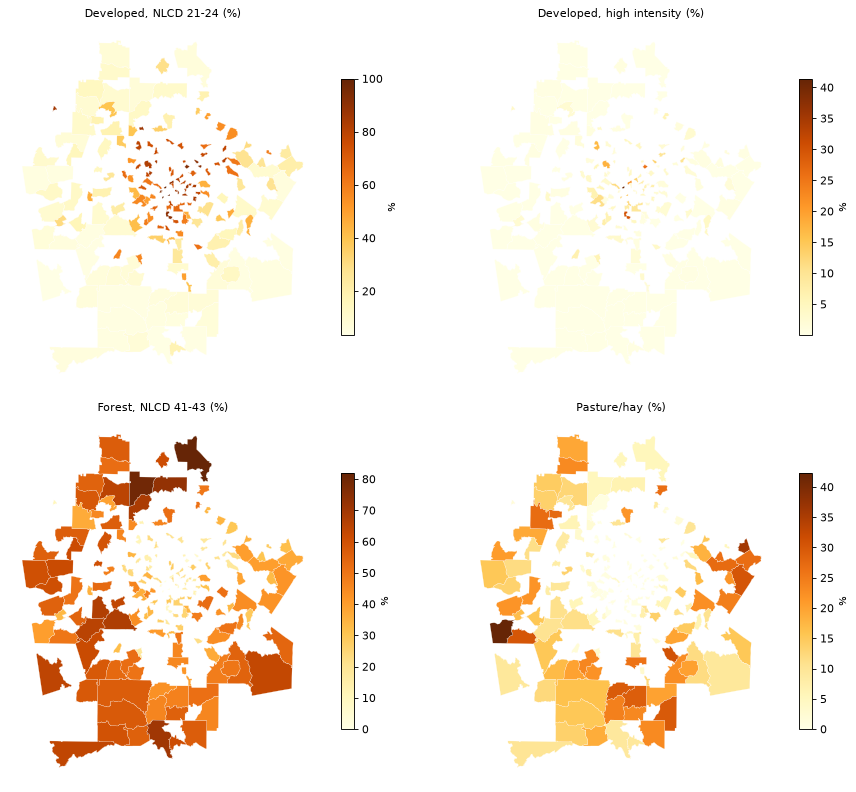

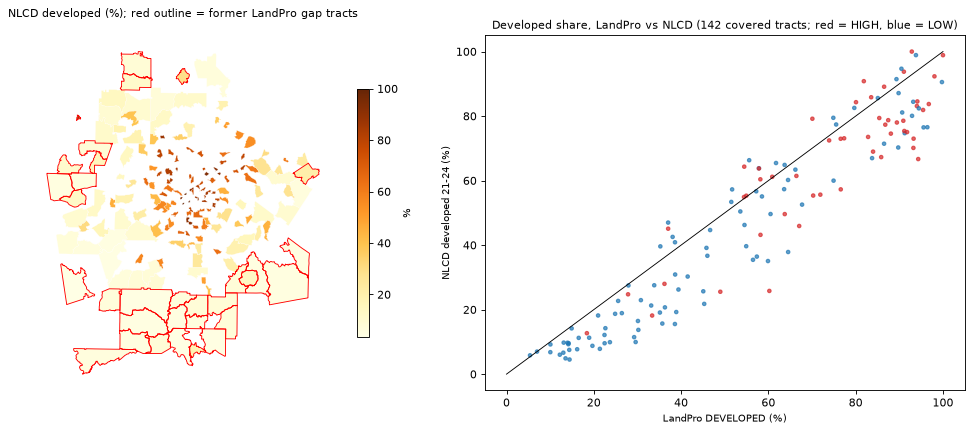

In [29]:
NLCD_MAP = {"nlcd11_pct_developed": "Developed, NLCD 21-24 (%)", "nlcd11_pct_developed_high_intensity": "Developed, high intensity (%)",
            "nlcd11_pct_forest": "Forest, NLCD 41-43 (%)", "nlcd11_pct_pasture_hay": "Pasture/hay (%)"}
plot_choropleths(tract_gdf, list(NLCD_MAP), list(NLCD_MAP.values()), legend_labels=["%"] * len(NLCD_MAP), cmap="YlOrBr",
                 savepath=FIGURES / "nlcd_2011_landcover_maps_tract.png")

fig, axes = plt.subplots(1, 2, figsize=(13, 5.5))
plot_choropleth(tract_gdf, "nlcd11_pct_developed", "NLCD developed (%); red outline = former LandPro gap tracts",
                ax=axes[0], cmap="YlOrBr", legend_label="%")
tract_gdf[gap].boundary.plot(ax=axes[0], color="red", linewidth=0.8)
axes[1].scatter(tract_gdf["lu_pct_developed"], tract_gdf["nlcd11_pct_developed"], s=10, c=colors, alpha=0.7)
axes[1].plot([0, 100], [0, 100], color="black", linewidth=0.8)
axes[1].set(xlabel="LandPro DEVELOPED (%)", ylabel="NLCD developed 21-24 (%)",
            title=f"Developed share, LandPro vs NLCD ({tract_gdf['lu_pct_developed'].notna().sum()} covered tracts; red = HIGH, blue = LOW)")
fig.tight_layout()
fig.savefig(FIGURES / "nlcd_2011_vs_landpro_tract.png", bbox_inches="tight")
plt.show()

## 12. Master table: overall QA

Every source is now joined onto `tract_gdf`, one validated one-to-one join at a time. This section
checks the assembled table:

- join coverage per source;
- a map of missing values per tract;
- a Spearman correlation heatmap;
- scatter plots of the RF training-fit prediction against four headline variables.

**Why Spearman.** The tract energy estimates are **totals**, so they scale with population, and most
predictors are skewed. Rank correlation is robust to both. It is descriptive only: no model is fitted
here.

**No observed energy.** `energy_actual_kwh` is NaN at tract level, so the correlations and scatter plots use
`pred_RF_train_kwh` in its place. This is a model output, so a correlation with a variable that the model
used as a predictor is not independent evidence.

The land-use shares exist only for the tracts fully covered by LandPro (Section 9), so they are
incomplete by design, and their correlations use those tracts only (pairwise complete). Likewise,
`rs_lai_mean` is missing for the tracts with no valid LAI pixel (Section 11). The NLCD land-cover
shares (Section 11.1) are complete for every study tract.

,n_columns,n_tracts_matched,n_tracts_complete
CBD distance,1,174,174
MARTA rail,4,174,174
Walkability,2,174,174
Microsoft buildings,5,174,174
Socioeconomic,356,174,171
Land use (LandPro),33,174,142
Air quality (CMAQ),14,174,174
Remote sensing,5,174,153
Land cover (NLCD 2011),18,174,174


C:\Users\irsra\atlanta-energy-morphology\.venv\Lib\site-packages\geopandas\geodataframe.py:1969: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  super().__setitem__(key, value)


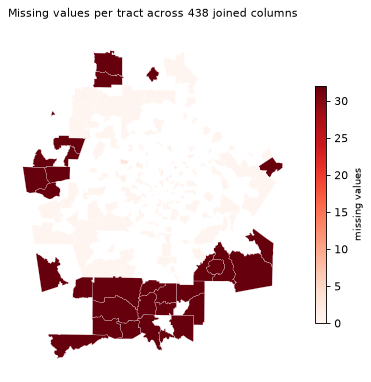

In [30]:
JOIN_GROUPS = {
    "CBD distance": ["Dist_CBD_mi"],
    "MARTA rail": ["MARTA_stations_in_tract", "has_MARTA_station", "Dist_MARTA_Rail_mi", "Nearest_MARTA_Station"],
    "Walkability": ["NatWalkInd_tract", "D3B_tract"],
    "Microsoft buildings": MS_COLS,
    "Socioeconomic": SE_COLS,
    "Land use (LandPro)": ["landpro_coverage_frac"] + LU_COLS,
    "Air quality (CMAQ)": AQ_COLS,
    "Remote sensing": RS_COLS,
    "Land cover (NLCD 2011)": NLCD_COLS,
}
coverage = pd.DataFrame({g: {"n_columns": len(c), "n_tracts_matched": tract_gdf[c].notna().any(axis=1).sum(),
                             "n_tracts_complete": tract_gdf[c].notna().all(axis=1).sum()} for g, c in JOIN_GROUPS.items()}).T
display(coverage)
assert (coverage["n_tracts_matched"] == len(tract_gdf)).all()

JOINED_COLS = sum(JOIN_GROUPS.values(), [])
plot_choropleth(tract_gdf.assign(n_missing=tract_gdf[JOINED_COLS].isna().sum(axis=1)), "n_missing",
                f"Missing values per tract across {len(JOINED_COLS)} joined columns", cmap="Reds", legend_label="missing values")
plt.show()

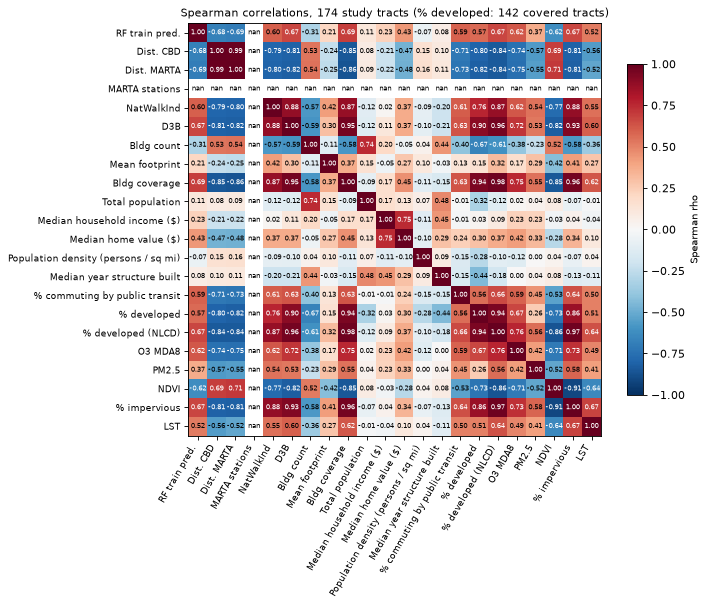

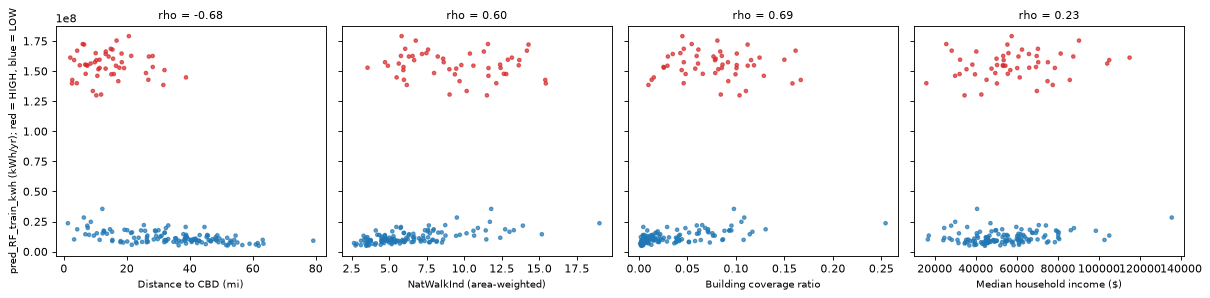

In [31]:
CORR_VARS = {
    "pred_RF_train_kwh": "RF train pred.", "Dist_CBD_mi": "Dist. CBD", "Dist_MARTA_Rail_mi": "Dist. MARTA",
    "MARTA_stations_in_tract": "MARTA stations", "NatWalkInd_tract": "NatWalkInd", "D3B_tract": "D3B",
    "ms_bldg_count": "Bldg count", "ms_mean_area_sqft": "Mean footprint", "ms_bldg_coverage_ratio": "Bldg coverage",
    **{c: name for name, c in KEY_SE.items()},
    "lu_pct_developed": "% developed", "nlcd11_pct_developed": "% developed (NLCD)", "aq_o3_mda8_jul2010": "O3 MDA8", "aq_pm25_avg_jul2010": "PM2.5",
    "rs_ndvi_mean": "NDVI", "rs_impervious_pct_mean": "% impervious", "rs_lst_c_mean": "LST",
}
corr = tract_gdf[list(CORR_VARS)].astype("float64").corr(method="spearman")
labels = list(CORR_VARS.values())
fig, ax = plt.subplots(figsize=(9, 7.5))
im = ax.imshow(corr, cmap="RdBu_r", vmin=-1, vmax=1)
ax.set_xticks(range(len(labels)), labels, rotation=60, ha="right", fontsize=8)
ax.set_yticks(range(len(labels)), labels, fontsize=8)
for (i, j), v in np.ndenumerate(corr.to_numpy()):
    ax.text(j, i, f"{v:.2f}", ha="center", va="center", fontsize=6, color="white" if abs(v) > 0.6 else "black")
fig.colorbar(im, ax=ax, shrink=0.8, label="Spearman rho")
ax.set_title(f"Spearman correlations, {len(tract_gdf)} study tracts (% developed: {tract_gdf['lu_pct_developed'].notna().sum()} covered tracts)")
fig.tight_layout()
plt.show()

SCATTER_VARS = {"Dist_CBD_mi": "Distance to CBD (mi)", "NatWalkInd_tract": "NatWalkInd (area-weighted)",
                "ms_bldg_coverage_ratio": "Building coverage ratio", KEY_SE["Median household income ($)"]: "Median household income ($)"}
fig, axes = plt.subplots(1, 4, figsize=(15, 3.8), sharey=True)
for ax, (col, lab) in zip(axes, SCATTER_VARS.items()):
    ax.scatter(tract_gdf[col], tract_gdf["pred_RF_train_kwh"], s=10, c=colors, alpha=0.7)
    ax.set(xlabel=lab, title=f"rho = {corr.loc[col, 'pred_RF_train_kwh']:.2f}")
axes[0].set_ylabel("pred_RF_train_kwh (kWh/yr); red = HIGH, blue = LOW")
fig.tight_layout()
plt.show()

## 13. Data dictionary and outputs

Every non-geometry column of the master table gets one dictionary row: description, unit, source and
method. The rows come from four places:
- the TIGER tract columns from `BASE_COLUMN_DOCS` (Section 3);
- socioeconomic columns from the codebook;
- land-use, air-quality, remote-sensing and land-cover columns from their class, field and raster lists
  (Sections 9 to 11.1);
- other derived columns from the table below.

The build fails if any column is undocumented. The dictionary is then put in the table's column order.

**Outputs.** Every file is a tract file. The ZIP outputs of notebook 01 and the interim layers it shares
(`cbd_atlanta.gpkg`, `marta_rail_stations.gpkg`, `epa_walkability.gpkg`, `ms_buildings.gpkg`) are not
written again.
- `data/processed/tract_data_dictionary.csv`
- `data/processed/tract_master.csv` and `tract_master.xlsx`: the master table without geometry.
- `data/processed/tract_landuse_coverage_gaps.csv`: the study tracts with LandPro coverage below 99%
  (Section 9.1).
- `data/interim/tract_joined.gpkg`: the master table, with geometry.
- Saved earlier: `tract_base.gpkg` (Section 3d).
- `figures/nlcd_2011_landcover_maps_tract.png` and `figures/nlcd_2011_vs_landpro_tract.png` (Section 11.1).

In [32]:
MS_SRC = "Microsoft US Building Footprints 2018-2020"
MARTA_SRC = "MARTA rail stations 2025"
MODEL_SRC = "Prior energy model workbooks (highEE_FullData.xlsx, lowEE_FullData.xlsx), sheet censusEstimates"
COORD_SRC = "Prior energy model workbooks (sheets Census Coordinates / testCoordinates)"
DERIVED_DOCS = pd.DataFrame(
    [
        ("pop", "Total population (equals se_v001)", "persons", "May_Zip_Tract_regular_June_2.xlsx (2011 ACS/Census), via socioeconomic_tract.csv", "se_v001 of the tract row with the same TractGeoID"),
        ("lat", "Latitude of the tract point used in the model workbooks", "degrees", COORD_SRC, "Column lat of the coordinates sheet, row-aligned with censusEstimates"),
        ("lon", "Longitude of the tract point used in the model workbooks", "degrees", COORD_SRC, "Column lon of the coordinates sheet, row-aligned with censusEstimates"),
        ("pred_RF_train_kwh", "Random-forest prediction, training fit (was RFnewCensus_RF)", "kWh/yr", MODEL_SRC, "Renamed; row-aligned with the coordinates sheet"),
        ("pred_RF_cv_kwh", "Random-forest prediction, cross-validated (was RFnewCensus_cv)", "kWh/yr", MODEL_SRC, "Renamed; row-aligned with the coordinates sheet"),
        ("pred_MATLAB_kwh", "MATLAB regression prediction, unreliable; many tract values are negative (was matlabnewCens)", "kWh/yr", MODEL_SRC, "Renamed; row-aligned with the coordinates sheet"),
        ("energy_actual_kwh", "Observed residential energy use: not available at tract level", "kWh/yr", "None (see method)",
         "NaN for every tract: observed residential energy is available only at ZIP level; source tract values are 0 placeholders"),
        ("cluster", "HIGH / LOW energy cluster of the workbook the tract comes from (analyst judgment call)", "category", "Prior energy model workbooks",
         "HIGH = highEE_FullData.xlsx, LOW = lowEE_FullData.xlsx; a tract in both workbooks keeps HIGH"),
        ("matlab_negative", "MATLAB prediction is negative (unreliable estimate)", "boolean", MODEL_SRC, "pred_MATLAB_kwh < 0"),
        ("TractGeoID", "Join key: 11-character zero-padded 2010 tract GEOID", "text", "TIGER/Line 2010 census tract", "GEOID10 as zero-padded string"),
        ("tract_area_sqft", "Planar tract polygon area (denominator of area metrics)", "sq ft", "TIGER/Line 2010 census tract", "geometry.area in EPSG:2240"),
        ("Dist_CBD_mi", "Euclidean distance from tract representative point to CBD representative point", "mi", "Atlanta CBD polygon (provided with the study data)", "Distance in EPSG:2240 ft / 5,280"),
        ("MARTA_stations_in_tract", "Number of MARTA rail stations within the tract", "count", MARTA_SRC, "Point-in-polygon (within); 0 where none"),
        ("has_MARTA_station", "Tract contains at least one MARTA rail station", "boolean", MARTA_SRC, "MARTA_stations_in_tract > 0"),
        ("Dist_MARTA_Rail_mi", "Euclidean distance from tract representative point to nearest MARTA rail station", "mi", MARTA_SRC, "sjoin_nearest in EPSG:2240 ft / 5,280"),
        ("Nearest_MARTA_Station", "Name of the nearest MARTA rail station", "text", MARTA_SRC, "sjoin_nearest (ties: first)"),
        ("NatWalkInd_tract", "EPA National Walkability Index", "index 1-20", "EPA NWI v3.0, block groups", "Area-weighted mean over tract x block-group overlay"),
        ("D3B_tract", "Pedestrian-oriented street-intersection density", "intersections / sq mi", "EPA NWI v3.0, block groups", "Area-weighted mean over tract x block-group overlay"),
        ("ms_bldg_count", "Number of Microsoft building footprints", "count", MS_SRC, "Buildings assigned by representative point within tract"),
        ("ms_sum_area_sqft", "Total building footprint area", "sq ft", MS_SRC, "Sum of footprint areas (EPSG:2240)"),
        ("ms_mean_area_sqft", "Mean building footprint area", "sq ft", MS_SRC, "Mean of footprint areas (EPSG:2240)"),
        ("ms_max_area_sqft", "Largest building footprint area", "sq ft", MS_SRC, "Max of footprint areas (EPSG:2240)"),
        ("ms_bldg_coverage_ratio", "Share of tract area covered by building footprints", "sq ft / sq ft", MS_SRC, "ms_sum_area_sqft / tract_area_sqft"),
    ],
    columns=["column", "description", "unit", "source", "method"],
)
se_rows = codebook[codebook["se_code"].isin(SE_COLS)]
se_docs = pd.DataFrame({
    "column": se_rows["se_code"], "description": se_rows["label"],
    "unit": np.select([se_rows["label_raw"].str.startswith("Percent"), se_rows["label_raw"].str.startswith("Number")], ["%", "count"], "see label"),
    "source": "May_Zip_Tract_regular_June_2.xlsx (2011 ACS/Census)",
    "method": np.where(se_rows["in_highEE_model"] | se_rows["in_lowEE_model"], "Direct TractGeoID match; cluster-model predictor", "Direct TractGeoID match"),
})
LANDPRO_SRC = "ARC LandPro 2012 (Atlanta Regional Commission)"
LU_METHOD = "Tract x LandPro overlay, EPSG:2240 areas; % of covered area; NaN unless landpro_coverage_frac >= 0.99"
lu_docs = pd.DataFrame(
    [("landpro_coverage_frac", "Share of tract area covered by LandPro polygons", "sq ft / sq ft", LANDPRO_SRC,
      "Sum of tract x LandPro overlay piece areas / tract_area_sqft; all tracts")]
    + [(c, f"Share of the LandPro-covered tract area in DE3 group {g}", "% of covered area", LANDPRO_SRC, LU_METHOD) for c, g in zip(LU_DE3_COLS, DE3_GROUPS)]
    + [(c, f"Share of the LandPro-covered tract area in land-use class {k} (LU_NAME)", "% of covered area", LANDPRO_SRC, LU_METHOD + "; 0 where absent")
       for c, k in zip(LU_CLASS_COLS, LU_CLASSES)],
    columns=["column", "description", "unit", "source", "method"],
)
aq_docs = pd.DataFrame(
    [(c, f"{desc} ({f}), July 2010 mean of daily values", unit, "EPA EQUATES CMAQ v5.3.2, 12US1 12 km grid, July 2010",
      "Mean of 31 daily values per cell; area-weighted mean over tract x grid-cell overlay (EPSG:2240)")
     for c, (f, (desc, unit)) in zip(AQ_COLS, AQ_FIELDS.items())],
    columns=["column", "description", "unit", "source", "method"],
)
RS_METHOD = "Zonal mean (as ArcGIS Zonal Statistics, MEAN): mean of the valid pixels whose centre lies in the tract, native EPSG:4326 grid"
rs_docs = pd.DataFrame(
    [(c, desc, unit, f"{source} ({f})", RS_METHOD) for c, (f, desc, unit, source, _) in RASTERS.items()]
    + [("rs_lai_valid_frac", "Share of the tract's LAI pixels with a valid (vegetated) value", "pixels / pixels",
        RASTERS["rs_lai_mean"][3], "Valid LAI pixels / all LAI pixels whose centre lies in the tract")],
    columns=["column", "description", "unit", "source", "method"],
)
NLCD_SRC = f"NLCD 2011 Land Cover, CONUS, 2011 edition (USGS, doi:10.5066/P97S2IID; {NLCD_PATH.name})"
NLCD_METHOD = "Zonal class share: pixels whose centre lies in the tract, native 30 m Albers equal-area grid; % of classified pixels"
nlcd_docs = pd.DataFrame(
    [(c, f"Share of the tract in NLCD {g} (classes {', '.join(map(str, NLCD_GROUPS[g]))})", "% of classified area", NLCD_SRC, NLCD_METHOD + "; sum of classes")
     for g, c in NLCD_GROUP_COLS.items()]
    + [(c, f"Share of the tract in NLCD class {k} ({NLCD_CLASSES[k]})", "% of classified area", NLCD_SRC, NLCD_METHOD)
       for k, c in NLCD_CLASS_COLS.items()]
    + [("nlcd11_valid_frac", "Share of the tract's NLCD pixels with a legend class", "pixels / pixels", NLCD_SRC,
        "Classified pixels / all pixels whose centre lies in the tract")],
    columns=["column", "description", "unit", "source", "method"],
)
base_docs = BASE_COLUMN_DOCS.assign(method="From the base layer, unchanged")
data_dictionary = pd.concat([base_docs, DERIVED_DOCS, se_docs, lu_docs, aq_docs, rs_docs, nlcd_docs]).set_index("column")
assert data_dictionary.index.is_unique, "a column is documented twice"
table_cols = list(tract_gdf.columns.drop("geometry"))
assert set(table_cols) <= set(data_dictionary.index), "undocumented columns"
data_dictionary = data_dictionary.loc[table_cols].reset_index()
data_dictionary.to_csv(PROCESSED / "tract_data_dictionary.csv", index=False)

tract_gdf.to_file(INTERIM / "tract_joined.gpkg", driver="GPKG")
master = tract_gdf.drop(columns="geometry")
master.to_csv(PROCESSED / "tract_master.csv", index=False)
master.to_excel(PROCESSED / "tract_master.xlsx", index=False)
print(f"tract_joined.gpkg: {tract_gdf.shape[0]} rows x {tract_gdf.shape[1]} columns; dictionary: {len(data_dictionary)} rows")
data_dictionary.head(45)

tract_joined.gpkg: 174 rows x 462 columns; dictionary: 461 rows


,column,description,unit,source,method
0,STATEFP10,State FIPS code (13 = Georgia),code,TIGER/Line 2010 census tract,"From the base layer, unchanged"
1,COUNTYFP10,County FIPS code,code,TIGER/Line 2010 census tract,"From the base layer, unchanged"
2,TRACTCE10,6-digit census tract code,code,TIGER/Line 2010 census tract,"From the base layer, unchanged"
3,GEOID10,State + county + tract FIPS; source of the Tra...,code,TIGER/Line 2010 census tract,"From the base layer, unchanged"
4,NAME10,Census tract number,text,TIGER/Line 2010 census tract,"From the base layer, unchanged"
5,NAMELSAD10,Census tract name with its legal/statistical a...,text,TIGER/Line 2010 census tract,"From the base layer, unchanged"
6,MTFCC10,MAF/TIGER feature class code,code,TIGER/Line 2010 census tract,"From the base layer, unchanged"
7,FUNCSTAT10,Functional status,code,TIGER/Line 2010 census tract,"From the base layer, unchanged"
8,ALAND10,Land area (not used; see tract_area_sqft),sq m,TIGER/Line 2010 census tract,"From the base layer, unchanged"
9,AWATER10,Water area,sq m,TIGER/Line 2010 census tract,"From the base layer, unchanged"


## 14. Pending / not yet joined

**Not yet in this pipeline:**
- TIGER 2012 primary/secondary roads (arterial density). The 2012 TIGER `prisecroads` file is
  identified but not yet added.
- Observed tract-level residential energy, which does not exist in the study data. `energy_actual_kwh`
  stays NaN until a source is found.

**Dropped from scope:** MARTA bus stops and routes, and NLCD tree canopy.

**ZIP-level counterpart.** `01_data_preparation.ipynb` builds the same table for the ZIP study units
(`data/processed/zipcode_master.csv`).